# Laboratorio 10 – CC3045 Deep Learning (Tasks 1, 2 y 3.1 a 3.5)
Explicabilidad: Grad-CAM/CAM sobre ResNet-18 (Task 1), SHAP sobre un modelo de crédito (Task 2), LIME tabular y contrafactuales (Task 3).
Todo el código usa PyTorch, NumPy y scikit-learn; Grad-CAM y CAM están escritos desde cero y la fórmula de Shapley de la Task 2.5 también.

In [1]:
import os, random, time, json, math, itertools, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from torchvision import models, transforms
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

# Semilla aleatoria (se reporta en el documento): SEED = 42
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight"})

RES = {}   # resultados numéricos que luego se insertan en el documento de Word
def save_res(): json.dump(RES, open("results/results_t1_t2.json", "w", encoding="utf8"), indent=1, default=float)
print("torch", torch.__version__, "| device:", device, "| SEED =", SEED)

torch 2.11.0+cu128 | device: cuda | SEED = 42


# Task 1 – Grad-CAM y CAM sobre ResNet-18

## Task 1.1 – Modelo, preprocesado e imágenes

In [2]:
# ResNet-18 con pesos preentrenados de ImageNet, en modo evaluación.
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights).to(device).eval()
CLASSES = weights.meta["categories"]

# Preprocesado pedido: lado corto a 256, recorte central 224x224 y normalización por canal de ImageNet.
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
geom = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
to_tensor, normalize = transforms.ToTensor(), transforms.Normalize(MEAN, STD)

IMG_FILES = {
    "a": "images/a_objeto_centrado.jpg",     # (a) objeto claro y centrado
    "b": "images/b_gato_y_perro.jpg",        # (b) dos objetos de clases distintas
    "c": "images/c_sofa_en_el_campo.jpg",    # (c) objeto fuera de su contexto habitual
}
def load_image(key):
    pil224 = geom(Image.open(IMG_FILES[key]).convert("RGB"))          # PIL 224x224 (sin normalizar)
    x = normalize(to_tensor(pil224)).unsqueeze(0).to(device)          # tensor 1x3x224x224 normalizado
    return pil224, x
IM = {k: load_image(k) for k in IMG_FILES}

@torch.no_grad()
def predict(x):
    logits = model(x)[0]
    return logits, F.softmax(logits, dim=0)

RES["t1_1"] = {}
for k in "abc":
    logits, probs = predict(IM[k][1])
    top = probs.topk(5)
    RES["t1_1"][k] = [{"idx": int(i), "name": CLASSES[int(i)], "p": float(p)} for p, i in zip(top.values, top.indices)]
    print(f"Imagen ({k}):")
    for r in RES["t1_1"][k]: print(f"   {r['idx']:4d}  {r['name']:<28s} {r['p']:.4f}")

Imagen (a):
    257  Great Pyrenees               0.7927
    222  kuvasz                       0.0706
    207  golden retriever             0.0436
    258  Samoyed                      0.0232
    249  malamute                     0.0131
Imagen (b):
    208  Labrador retriever           0.3945
    209  Chesapeake Bay retriever     0.0497
    282  tiger cat                    0.0340
    159  Rhodesian ridgeback          0.0300
    162  beagle                       0.0288
Imagen (c):
    435  bathtub                      0.3606
    876  tub                          0.2887
    463  bucket                       0.0538
    412  ashcan                       0.0335
    730  plow                         0.0191


Recuadro (c): (54, 137, 184, 208) | fracción del área: 0.184


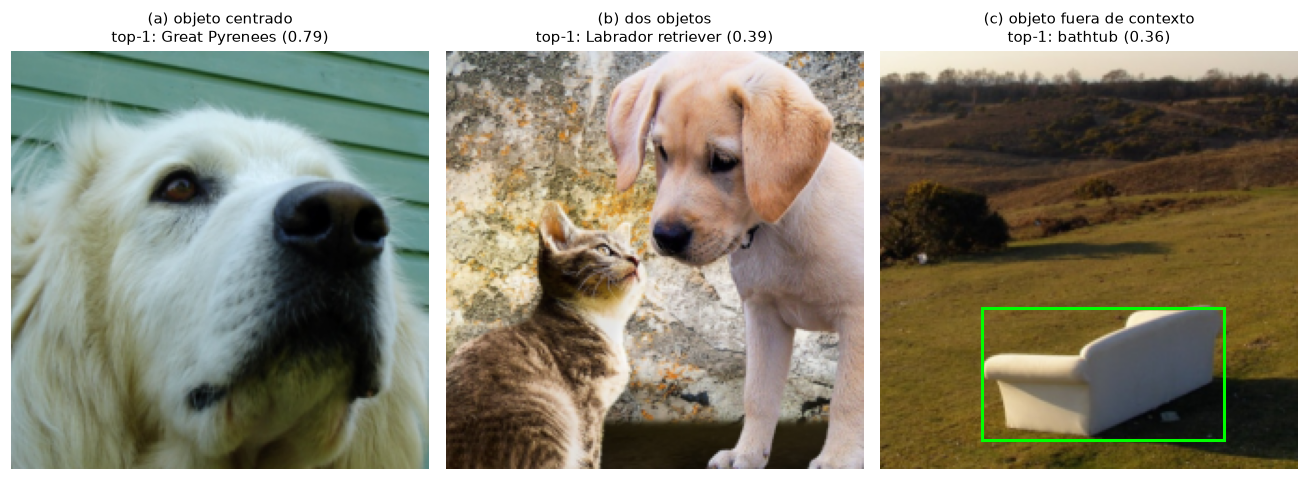

In [3]:
# Recuadro del objeto de la imagen (c) en coordenadas de la imagen de 224x224: (x0, y0, x1, y1), medido sobre la imagen recortada.
BOX_C = (54, 137, 184, 208)
RES["t1_1"]["box_c"] = BOX_C
RES["t1_1"]["box_c_area_frac"] = (BOX_C[2]-BOX_C[0])*(BOX_C[3]-BOX_C[1])/224**2
print("Recuadro (c):", BOX_C, "| fracción del área:", round(RES["t1_1"]["box_c_area_frac"], 4))

fig, ax = plt.subplots(1, 3, figsize=(12, 4.4))
titles = {"a": "(a) objeto centrado", "b": "(b) dos objetos", "c": "(c) objeto fuera de contexto"}
for a, k in zip(ax, "abc"):
    a.imshow(IM[k][0]); a.axis("off")
    a.set_title(f"{titles[k]}\ntop-1: {RES['t1_1'][k][0]['name']} ({RES['t1_1'][k][0]['p']:.2f})", fontsize=10)
x0, y0, x1, y1 = BOX_C
ax[2].add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec="lime", lw=2))
plt.tight_layout(); plt.savefig("figures/t1_1_imagenes.png"); plt.show()

## Task 1.2 – Grad-CAM desde cero sobre `layer4`
Con $A^k\in\mathbb{R}^{7\times7}$ (512 canales) las activaciones de `layer4`:

$$\alpha_k^c=\frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}},\qquad L^c=\mathrm{ReLU}\Big(\sum_k\alpha_k^c A^k\Big)$$

El gradiente se obtiene retropropagando desde el **logit** $y^c$ (antes del softmax).

a {'cls': 257, 'name': 'Great Pyrenees', 'p': 0.792654812335968, 'logit': 13.268692970275879}
b {'cls': 208, 'name': 'Labrador retriever', 'p': 0.39454516768455505, 'logit': 9.694001197814941}
b2 {'cls': 282, 'name': 'tiger cat', 'p': 0.03402276709675789, 'logit': 7.243297576904297}
c {'cls': 435, 'name': 'bathtub', 'p': 0.36060023307800293, 'logit': 10.250008583068848}


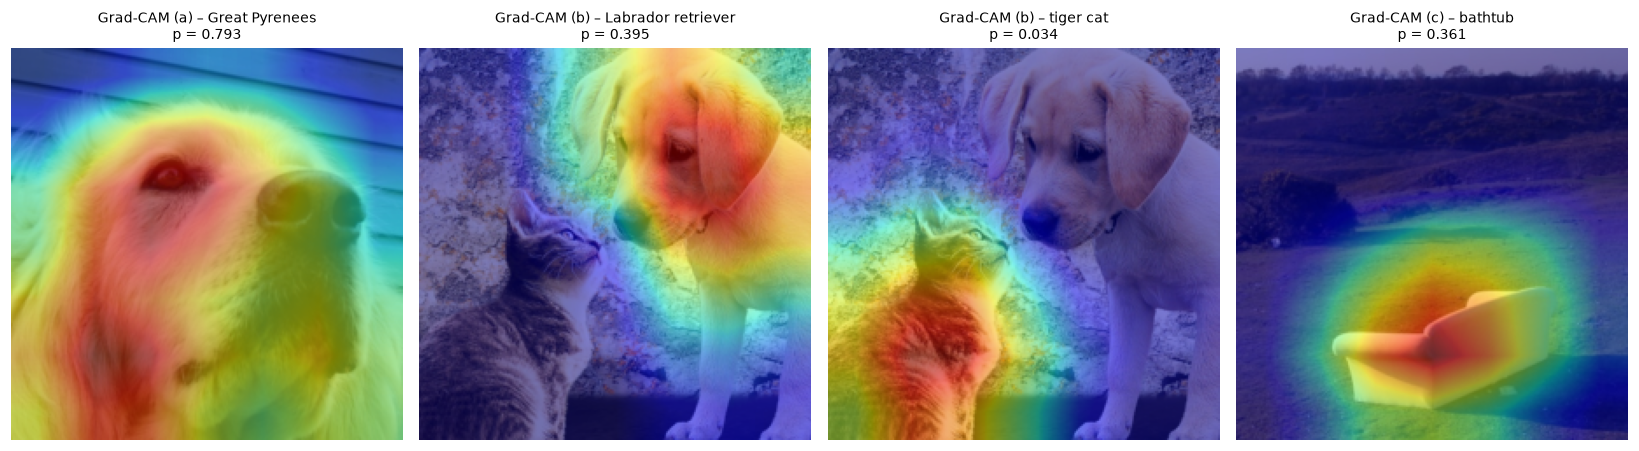

In [4]:
class GradCAM:
    """Grad-CAM con un hook de avance (activaciones A) y un hook de retroceso (dy^c/dA) sobre layer4."""
    def __init__(self, net, layer):
        self.net, self.A, self.dA = net, None, None
        self.h1 = layer.register_forward_hook(self._fwd)
        self.h2 = layer.register_full_backward_hook(self._bwd)
    def _fwd(self, module, inp, out):  self.A = out.detach()                 # A: 1x512x7x7
    def _bwd(self, module, gin, gout): self.dA = gout[0].detach()            # dy^c/dA: 1x512x7x7

    def __call__(self, x, c=None):
        self.net.zero_grad()
        logits = self.net(x)
        if c is None: c = int(logits.argmax(1))                              # clase de mayor probabilidad
        logits[0, c].backward()                                              # retropropaga desde el LOGIT y^c
        A, dA = self.A[0], self.dA[0]                                        # 512x7x7
        alpha = dA.mean(dim=(1, 2))                                          # alpha_k = promedio espacial del gradiente
        L_raw = (alpha[:, None, None] * A).sum(0)                            # sum_k alpha_k A^k (7x7), sin ReLU
        L = F.relu(L_raw)                                                    # L^c = ReLU(...)
        up = F.interpolate(L[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        cam224 = (up - up.min()) / (up.max() - up.min() + 1e-12)             # normalización min-max
        return dict(c=c, logit=float(logits[0, c]), alpha=alpha, A=A, dA=dA, L_raw=L_raw, L=L, cam224=cam224)
    def remove(self): self.h1.remove(); self.h2.remove()

gradcam = GradCAM(model, model.layer4)

def overlay(ax, pil, cam, title, alpha=0.5):
    ax.imshow(pil); ax.imshow(cam.cpu().numpy(), cmap="jet", alpha=alpha, vmin=0, vmax=1); ax.axis("off"); ax.set_title(title, fontsize=9)

# Clase del "segundo objeto" de la imagen (b): la mejor clase de la otra especie (perros: 151-268, gatos: 281-285)
_, pb = predict(IM["b"][1]); top_b = int(pb.argmax())
rng_other = range(281, 286) if 151 <= top_b <= 268 else range(151, 269)
cls_b2 = max(rng_other, key=lambda i: float(pb[i]))

GC = {}
GC["a"]  = gradcam(IM["a"][1])
GC["b"]  = gradcam(IM["b"][1])
GC["b2"] = gradcam(IM["b"][1], c=cls_b2)
GC["c"]  = gradcam(IM["c"][1])
RES["t1_2"] = {k: {"cls": v["c"], "name": CLASSES[v["c"]], "p": float(predict(IM[k[0]][1])[1][v["c"]]), "logit": v["logit"]} for k, v in GC.items()}
for k, v in RES["t1_2"].items(): print(k, v)

fig, ax = plt.subplots(1, 4, figsize=(15, 4.2))
for a, k, im in zip(ax, ["a", "b", "b2", "c"], ["a", "b", "b", "c"]):
    r = RES["t1_2"][k]
    overlay(a, IM[im][0], GC[k]["cam224"], f"Grad-CAM ({im}) – {r['name']}\np = {r['p']:.3f}")
plt.tight_layout(); plt.savefig("figures/t1_2_gradcam.png"); plt.show()

## Task 1.3 – CAM desde los pesos de `fc` y verificaciones
$M^c_{ij}=\sum_k w^c_kA^k_{ij}$, y como el modelo termina en promedio global + lineal: $y^c=\frac1Z\sum_{ij}M^c_{ij}+b_c$ con $Z=49$.

img |  (1/Z)ΣM + b    logit y^c  |err| (b) |  max|Z·L − M| | max|err| ReLU+norm
  a |    13.268692    13.268693   9.54e-07 |      2.86e-06 |           1.19e-07
  b |     9.694000     9.694001   9.54e-07 |      3.81e-06 |           1.19e-07
 b2 |     7.243298     7.243298   0.00e+00 |      3.81e-06 |           1.19e-07
  c |    10.250010    10.250009   9.54e-07 |      3.81e-06 |           5.96e-08


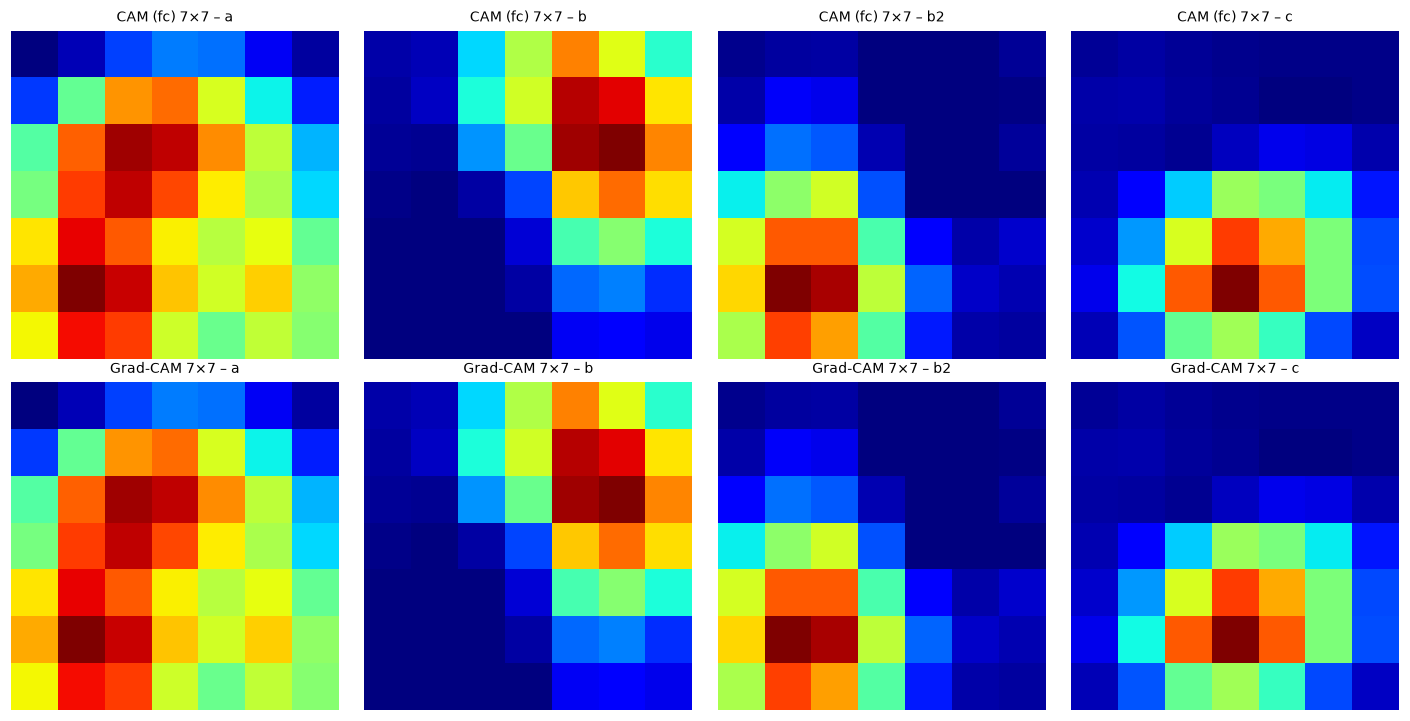

In [5]:
W, bias = model.fc.weight.detach(), model.fc.bias.detach()     # 1000x512, 1000
Z = 49
def reduce_map(m):                                              # ReLU + normalización min-max
    m = F.relu(m); return (m - m.min()) / (m.max() - m.min() + 1e-12)

RES["t1_3"] = {}
CAMS = {}
print(f"{'img':>3} | {'(1/Z)ΣM + b':>12} {'logit y^c':>12} {'|err| (b)':>10} | {'max|Z·L − M|':>13} | {'max|err| ReLU+norm':>18}")
for k in ["a", "b", "b2", "c"]:
    g = GC[k]; c = g["c"]
    M = torch.einsum("k,kij->ij", W[c], g["A"])                                  # (a) CAM sin gradientes
    score = M.sum() / Z + bias[c]                                                # (b) descomposición del puntaje
    err_b = abs(float(score) - g["logit"])
    err_c = float((Z * g["L_raw"] - M).abs().max())                              # (c) Z·L^c (sin ReLU ni norm.) vs M^c
    err_d = float((reduce_map(g["L_raw"]) - reduce_map(M)).abs().max())          # (d) tras ReLU + min-max
    RES["t1_3"][k] = dict(score=float(score), logit=g["logit"], err_b=err_b, err_c=err_c, err_d=err_d)
    CAMS[k] = M
    print(f"{k:>3} | {float(score):12.6f} {g['logit']:12.6f} {err_b:10.2e} | {err_c:13.2e} | {err_d:18.2e}")

fig, ax = plt.subplots(2, 4, figsize=(13, 6.6))
for j, k in enumerate(["a", "b", "b2", "c"]):
    ax[0, j].imshow(reduce_map(CAMS[k]).cpu(), cmap="jet", vmin=0, vmax=1); ax[0, j].set_title(f"CAM (fc) 7×7 – {k}", fontsize=9)
    ax[1, j].imshow(reduce_map(GC[k]["L_raw"]).cpu(), cmap="jet", vmin=0, vmax=1); ax[1, j].set_title(f"Grad-CAM 7×7 – {k}", fontsize=9)
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig("figures/t1_3_cam_vs_gradcam.png"); plt.show()

## Task 1.4 – Análisis con los resultados propios

### (a) $\alpha_k^c$ numérico frente a $w_k^c/Z$ (imagen (a))

In [6]:
g, c = GC["a"], GC["a"]["c"]
top5 = W[c].topk(5).indices                                    # cinco canales de mayor peso w_k^c
rows = []
for k in top5.tolist():
    a_num, a_th = float(g["alpha"][k]), float(W[c, k] / Z)
    rows.append(dict(canal=k, w=float(W[c, k]), alpha=a_num, w_sobre_Z=a_th, err_rel=abs(a_num - a_th) / abs(a_th)))
df_alpha = pd.DataFrame(rows); print(df_alpha.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
# ¿es dy^c/dA_ij^k realmente igual en las 49 posiciones? dispersión espacial del gradiente por canal
spread = (g["dA"] - (W[c] / Z)[:, None, None]).abs().amax()
print("max |dy/dA_ij^k − w_k/Z| sobre los 512 canales y 49 posiciones:", float(spread))
print("max error relativo de alpha sobre los 512 canales:", float(((g['alpha'] - W[c]/Z).abs() / (W[c]/Z).abs()).max()))
RES["t1_4a"] = dict(rows=rows, spread=float(spread), max_rel_all=float(((g['alpha'] - W[c]/Z).abs() / (W[c]/Z).abs()).max()), cls=c)

 canal          w        alpha    w_sobre_Z       err_rel
    31 0.30468294 0.0062180185 0.0062180189 7.4889011e-08
   242 0.22929093 0.0046794065 0.0046794065             0
   362 0.22662991 0.0046250997 0.0046251002 1.0068134e-07
   127 0.20768896 0.0042385501 0.0042385501             0
    83 0.20473976 0.0041783624 0.0041783624             0
max |dy/dA_ij^k − w_k/Z| sobre los 512 canales y 49 posiciones: 0.0
max error relativo de alpha sobre los 512 canales: 1.7372512672864104e-07


### (b) Imagen (b): ¿discrimina el mapa entre las dos clases?

{'iou224': 0.0, 'iou7': 0.0, 'cls1': 'Labrador retriever', 'cls2': 'tiger cat', 'centroid1': (155.7541046142578, 78.37948608398438), 'centroid2': (67.94343566894531, 156.73178100585938), 'p1': 0.39454516768455505, 'p2': 0.03402276709675789, 'corr': -0.6708921518390946}


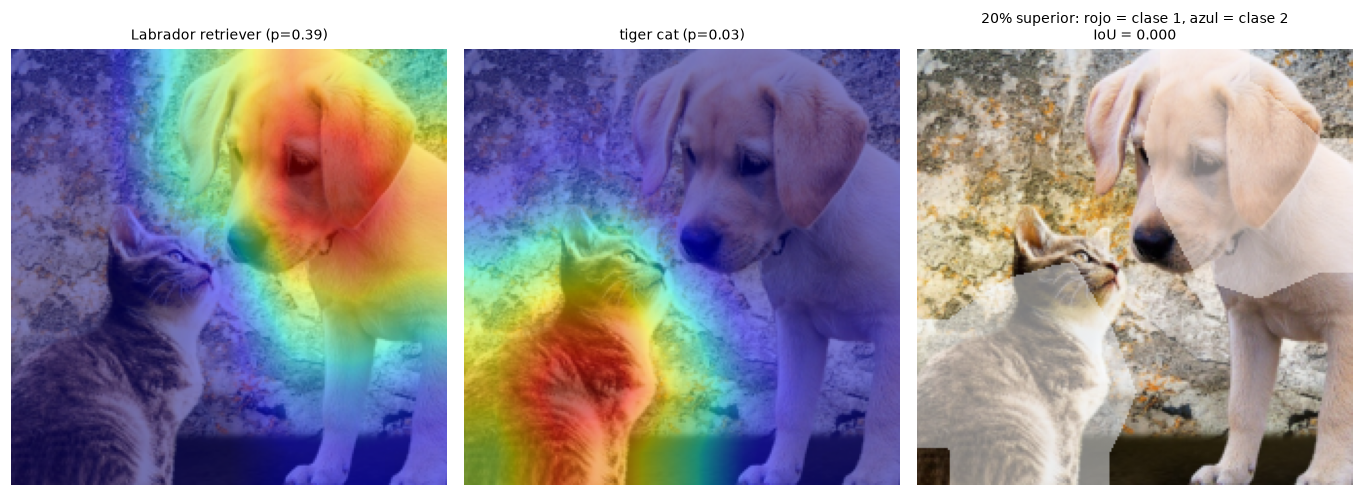

In [7]:
def top_set(m, frac=0.20):
    thr = torch.quantile(m.flatten(), 1 - frac); return m >= thr
def iou(a, b): return float((a & b).sum() / (a | b).sum())
m1, m2 = GC["b"]["cam224"], GC["b2"]["cam224"]
iou224 = iou(top_set(m1), top_set(m2))
# mismo cálculo sobre el mapa original 7x7 (20% de 49 celdas = 10 celdas)
l1, l2 = reduce_map(GC["b"]["L_raw"]), reduce_map(GC["b2"]["L_raw"])
k10 = lambda m: torch.zeros(49, dtype=torch.bool, device=m.device).scatter_(0, m.flatten().topk(10).indices, True)
iou7 = iou(k10(l1), k10(l2))
def centroid(m):
    ys, xs = torch.meshgrid(torch.arange(224, device=m.device), torch.arange(224, device=m.device), indexing="ij")
    return float((m * xs).sum() / m.sum()), float((m * ys).sum() / m.sum())
RES["t1_4b"] = dict(iou224=iou224, iou7=iou7, cls1=RES["t1_2"]["b"]["name"], cls2=RES["t1_2"]["b2"]["name"],
                    centroid1=centroid(m1), centroid2=centroid(m2),
                    p1=RES["t1_2"]["b"]["p"], p2=RES["t1_2"]["b2"]["p"],
                    corr=float(np.corrcoef(m1.flatten().cpu(), m2.flatten().cpu())[0, 1]))
print(RES["t1_4b"])

fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.4))
overlay(ax[0], IM["b"][0], m1, f"{RES['t1_2']['b']['name']} (p={RES['t1_2']['b']['p']:.2f})")
overlay(ax[1], IM["b"][0], m2, f"{RES['t1_2']['b2']['name']} (p={RES['t1_2']['b2']['p']:.2f})")
ax[2].imshow(IM["b"][0]); ax[2].axis("off")
ax[2].imshow(np.ma.masked_where(~top_set(m1).cpu().numpy(), np.ones((224, 224))), cmap="Reds", alpha=0.5)
ax[2].imshow(np.ma.masked_where(~top_set(m2).cpu().numpy(), np.ones((224, 224))), cmap="Blues", alpha=0.5)
ax[2].set_title(f"20% superior: rojo = clase 1, azul = clase 2\nIoU = {iou224:.3f}", fontsize=9)
plt.tight_layout(); plt.savefig("figures/t1_4b_dos_clases.png"); plt.show()

### (c) Imagen (c): masa dentro del recuadro y prueba causal

original                     p(bathtub) = 0.3606 | top-1: bathtub (0.361)
fondo gris (solo objeto)     p(bathtub) = 0.0107 | top-1: paper towel (0.233)
objeto gris (solo fondo)     p(bathtub) = 0.0007 | top-1: alp (0.234)
p(studio couch) = 0.0003 (posición 86 de 1000)
masa dentro del recuadro: 0.4981 | fracción del área: 0.184 | razón: 2.708


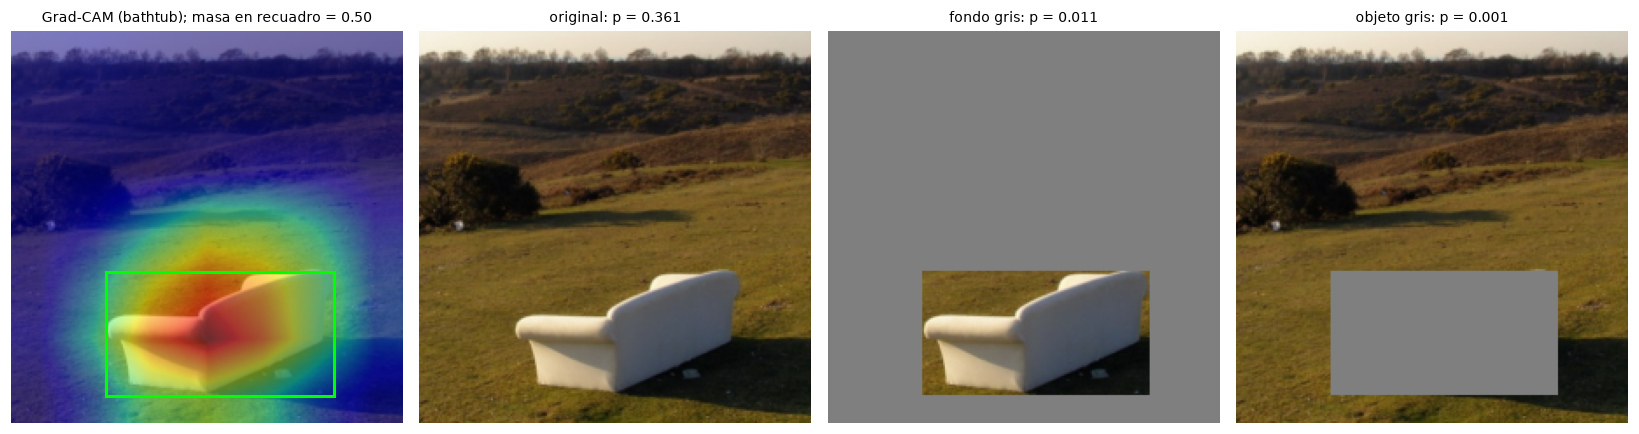

In [8]:
x0, y0, x1, y1 = BOX_C
cam = GC["c"]["cam224"]; c_c = GC["c"]["c"]
mass_in = float(cam[y0:y1, x0:x1].sum() / cam.sum())
area_frac = RES["t1_1"]["box_c_area_frac"]

def to_input(pil_or_arr):                                         # PIL/array [0,1] -> tensor normalizado
    return normalize(to_tensor(pil_or_arr)).unsqueeze(0).to(device) if isinstance(pil_or_arr, Image.Image) else normalize(pil_or_arr).unsqueeze(0).to(device)
base = to_tensor(IM["c"][0])                                      # 3x224x224 en [0,1]
gray = torch.full_like(base, 0.5)                                 # gris medio
outside_gray = gray.clone(); outside_gray[:, y0:y1, x0:x1] = base[:, y0:y1, x0:x1]     # fondo -> gris, objeto intacto
inside_gray = base.clone();  inside_gray[:, y0:y1, x0:x1] = 0.5                         # objeto -> gris, fondo intacto
res_c = {}
for name, img in [("original", base), ("fondo gris (solo objeto)", outside_gray), ("objeto gris (solo fondo)", inside_gray)]:
    _, p = predict(to_input(img)); top1 = int(p.argmax())
    res_c[name] = dict(p_clase=float(p[c_c]), top1=CLASSES[top1], p_top1=float(p[top1]))
    print(f"{name:<28s} p({CLASSES[c_c]}) = {float(p[c_c]):.4f} | top-1: {CLASSES[top1]} ({float(p[top1]):.3f})")
# clase ImageNet "esperada" del objeto: studio couch (831); se reporta su probabilidad y su posición en el ranking
_, p0 = predict(to_input(base)); rank_couch = int((p0 > p0[831]).sum()) + 1
print(f"p(studio couch) = {float(p0[831]):.4f} (posición {rank_couch} de 1000)")
RES["t1_4c"] = dict(p_couch=float(p0[831]), rank_couch=rank_couch, mass_in=mass_in, area_frac=area_frac, ratio=mass_in/area_frac, cls=CLASSES[c_c], tests=res_c)
print("masa dentro del recuadro:", round(mass_in, 4), "| fracción del área:", round(area_frac, 4), "| razón:", round(mass_in/area_frac, 3))

fig, ax = plt.subplots(1, 4, figsize=(15, 4.2))
overlay(ax[0], IM["c"][0], cam, f"Grad-CAM – {CLASSES[c_c]}")
ax[0].add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec="lime", lw=2)); ax[0].set_title(f"Grad-CAM ({CLASSES[c_c]}); masa en recuadro = {mass_in:.2f}", fontsize=9)
for a, (name, img) in zip(ax[1:], [("original", base), ("fondo gris", outside_gray), ("objeto gris", inside_gray)]):
    a.imshow(img.permute(1, 2, 0).numpy()); a.axis("off")
    key = {"original": "original", "fondo gris": "fondo gris (solo objeto)", "objeto gris": "objeto gris (solo fondo)"}[name]
    a.set_title(f"{name}: p = {res_c[key]['p_clase']:.3f}", fontsize=9)
plt.tight_layout(); plt.savefig("figures/t1_4c_prueba_causal.png"); plt.show()
save_res()

# Task 2 – SHAP sobre German Credit

## Task 2.1 – Datos y modelo

In [9]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance
import shap

try:
    datos = fetch_openml("credit-g", version=1, as_frame=True)
    X_raw, y_raw = datos.data.copy(), datos.target
    FUENTE = "fetch_openml"
except Exception as e:
    # En esta red el certificado de api.openml.org no es confiable para Python; se usa el mismo ARFF (OpenML data id 31, credit-g v1),
    # descargado de https://www.openml.org/data/v1/download/31/credit-g.arff, con las categorías en el orden declarado en el ARFF.
    print("fetch_openml falló:", type(e).__name__, "-> se usa data/credit-g.arff")
    from scipy.io import arff
    raw, meta = arff.loadarff("data/credit-g.arff")
    df = pd.DataFrame(raw)
    for c in meta.names():
        if meta[c][0] == "nominal":
            df[c] = pd.Categorical(df[c].str.decode("utf-8"), categories=list(meta[c][1]))
    y_raw = df.pop("class"); X_raw = df
    FUENTE = "ARFF local (OpenML data id 31)"
print("fuente de los datos:", FUENTE)
y = (y_raw.astype(str) == "good").astype(int).to_numpy()                      # good = 1, bad = 0
cat_cols = [c for c in X_raw.columns if str(X_raw[c].dtype) == "category"]
num_cols = [c for c in X_raw.columns if c not in cat_cols]
print(len(X_raw), "solicitudes |", len(num_cols), "numéricas |", len(cat_cols), "categóricas |", "good:", int(y.sum()), "bad:", int((1-y).sum()))

# Codificador ordinal: los códigos son ARBITRARIOS (según el orden de las categorías); se tratan como numéricos (limitación)
enc = OrdinalEncoder(categories=[list(X_raw[c].cat.categories) for c in cat_cols]).fit(X_raw[cat_cols])
X = X_raw.copy()
X[cat_cols] = enc.transform(X_raw[cat_cols])
X = X.astype(float); FEATS = list(X.columns)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
gbm = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(Xtr, ytr)
f_logodds = lambda D: gbm.decision_function(D)                    # salida del modelo en log-odds
acc = accuracy_score(yte, gbm.predict(Xte)); auc = roc_auc_score(yte, gbm.predict_proba(Xte)[:, 1])
RES["t2_1"] = dict(n=len(X), n_num=len(num_cols), n_cat=len(cat_cols), n_train=len(Xtr), n_test=len(Xte), acc=acc, auc=auc,
                   good_train=float(ytr.mean()), good_test=float(yte.mean()))
print(f"train={len(Xtr)} test={len(Xte)} | exactitud = {acc:.4f} | AUC = {auc:.4f}")

# Fondo de 100 instancias de entrenamiento elegidas al azar (se reutiliza en todo el Task 2)
rng = np.random.RandomState(SEED)
bg_idx = rng.choice(len(Xtr), 100, replace=False)
BG = Xtr.iloc[bg_idx]

fuente de los datos: fetch_openml
1000 solicitudes | 7 numéricas | 13 categóricas | good: 700 bad: 300
train=800 test=200 | exactitud = 0.7800 | AUC = 0.7685


## Task 2.2 – Valores SHAP (TreeSHAP intervencional, log-odds)

In [10]:
expl = shap.TreeExplainer(gbm, data=BG, feature_perturbation="interventional", model_output="raw")
phi = expl.shap_values(Xte)                                        # (200, 20) en log-odds
base = float(np.ravel(expl.expected_value)[0])
fx = f_logodds(Xte)                                                # f(x) en log-odds

# (a) eficiencia: base + sum phi_j = f(x)
eff_err = np.abs(base + phi.sum(1) - fx)
# (b) valor base = promedio de la salida del modelo sobre el fondo
base_bg = float(f_logodds(BG).mean())
print(f"(a) max |base + Σφ − f(x)| = {eff_err.max():.3e}  (media {eff_err.mean():.3e})")
print(f"(b) valor base SHAP = {base:.8f} | promedio f sobre el fondo = {base_bg:.8f} | dif = {abs(base-base_bg):.2e}")

# (c) importancia global y por permutación (AUC, 10 repeticiones)
I_shap = np.abs(phi).mean(0)
pi = permutation_importance(gbm, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=SEED)
I_perm = pi.importances_mean
order_s, order_p = np.argsort(-I_shap), np.argsort(-I_perm)
rho = spearmanr(I_shap, I_perm).correlation
print("\nTop-5 |φ| medio:      ", [(FEATS[i], round(float(I_shap[i]), 4)) for i in order_s[:5]])
print("Top-5 permutación (AUC):", [(FEATS[i], round(float(I_perm[i]), 4)) for i in order_p[:5]])
print(f"Spearman entre los rankings completos: {rho:.4f}")
RES["t2_2"] = dict(eff_max=float(eff_err.max()), eff_mean=float(eff_err.mean()), base=base, base_bg=base_bg,
                   I_shap={FEATS[i]: float(I_shap[i]) for i in range(20)}, I_perm={FEATS[i]: float(I_perm[i]) for i in range(20)},
                   I_perm_std={FEATS[i]: float(pi.importances_std[i]) for i in range(20)},
                   top5_shap=[FEATS[i] for i in order_s[:5]], top5_perm=[FEATS[i] for i in order_p[:5]], spearman=float(rho))

(a) max |base + Σφ − f(x)| = 5.997e-08  (media 1.298e-08)
(b) valor base SHAP = 1.28564395 | promedio f sobre el fondo = 1.28564395 | dif = 0.00e+00



Top-5 |φ| medio:       [('checking_status', 0.7496), ('credit_amount', 0.4869), ('duration', 0.3933), ('savings_status', 0.3502), ('purpose', 0.3402)]
Top-5 permutación (AUC): [('checking_status', 0.1188), ('duration', 0.0724), ('credit_amount', 0.068), ('credit_history', 0.039), ('savings_status', 0.0304)]
Spearman entre los rankings completos: 0.7549


aprobado: posición 157 p = 0.9003 | rechazado: posición 180 p = 0.0997


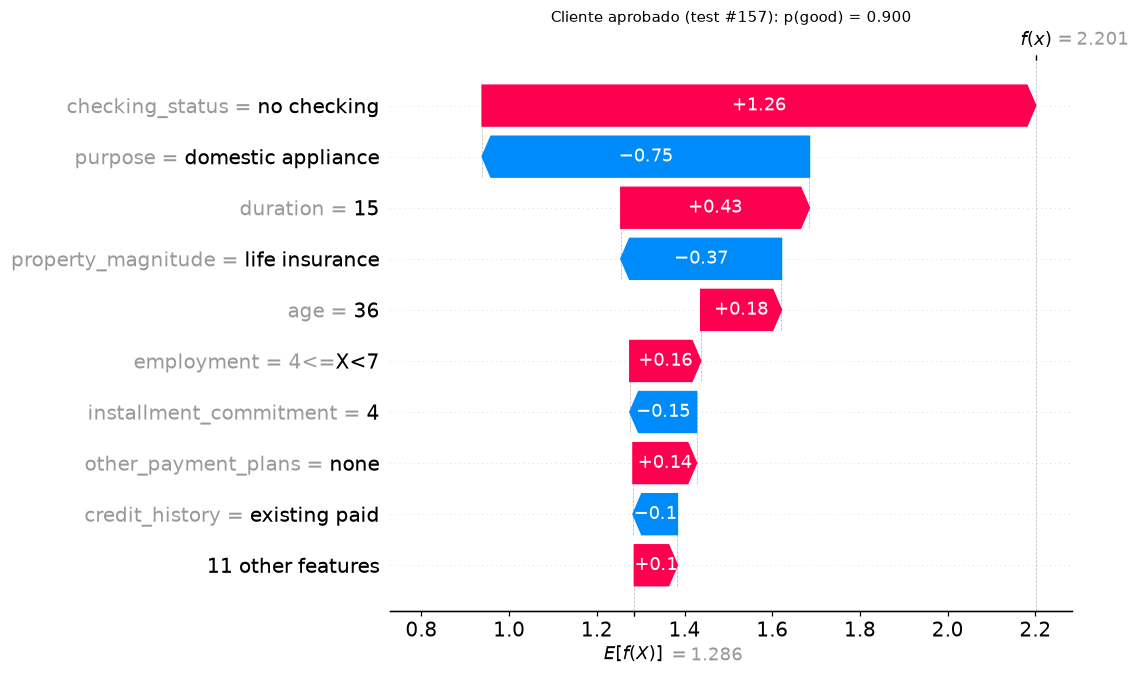

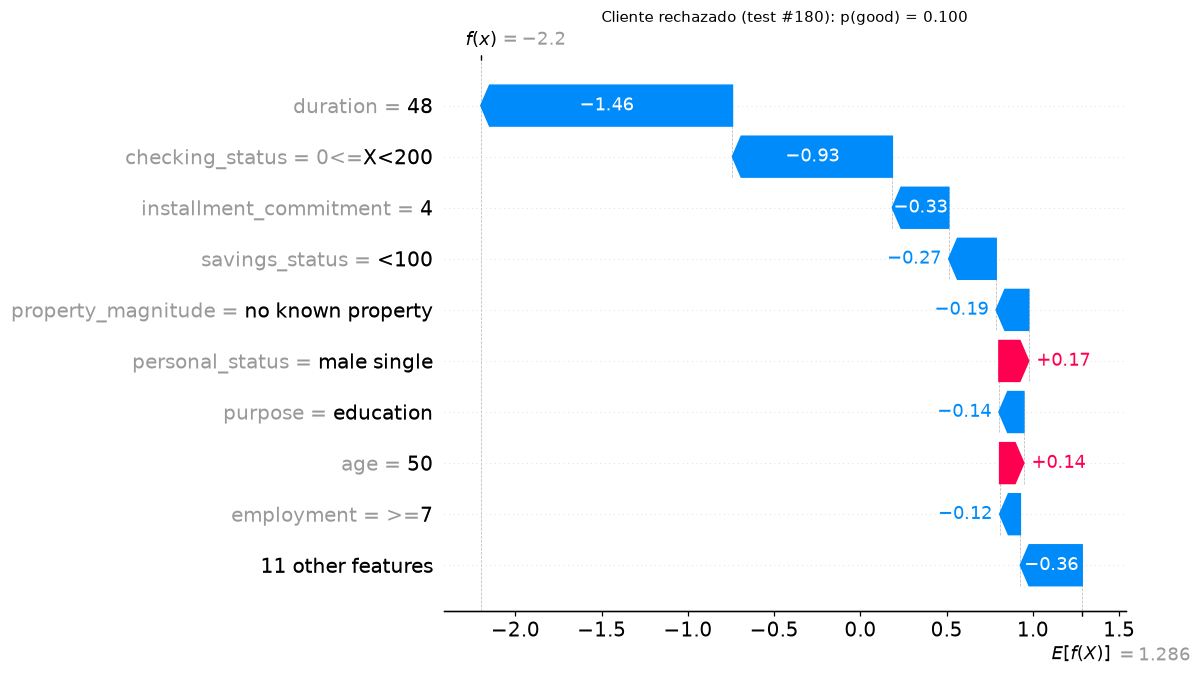

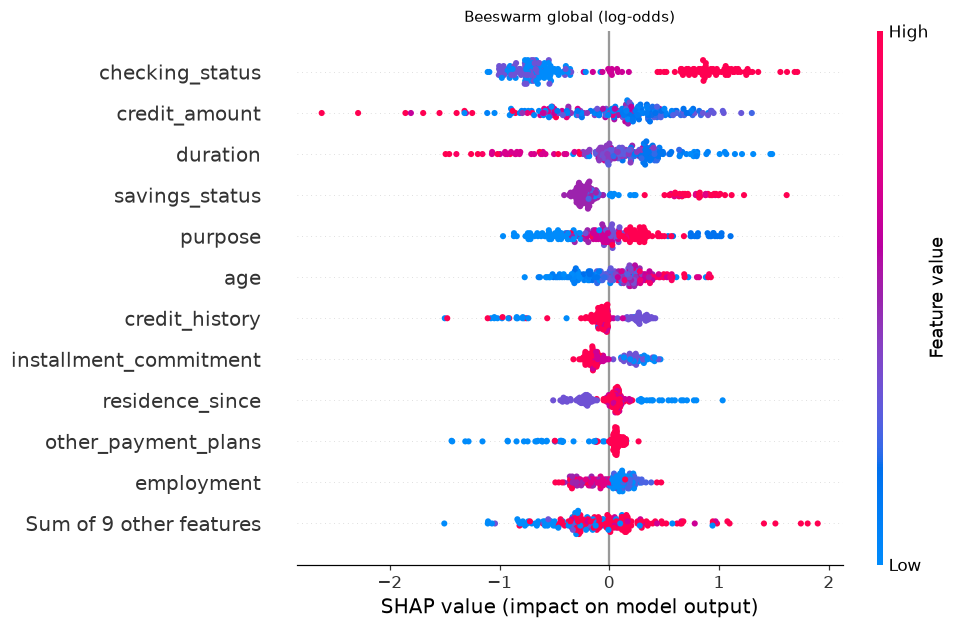

[{'feat': 'checking_status', 'valor': 'no checking', 'phi': 1.2623228674312121}, {'feat': 'purpose', 'valor': 'domestic appliance', 'phi': -0.746336517445743}, {'feat': 'duration', 'valor': '15', 'phi': 0.4300927376560867}]
[{'feat': 'duration', 'valor': '48', 'phi': -1.4585865248832852}, {'feat': 'checking_status', 'valor': '0<=X<200', 'phi': -0.9268442213558592}, {'feat': 'installment_commitment', 'valor': '4', 'phi': -0.326989728261251}]


In [11]:
# (d) clientes de prueba: p(good) > 0.8 (aprobado) y p(good) < 0.2 (rechazado)
p_te = gbm.predict_proba(Xte)[:, 1]
i_ok  = int(np.argmin(np.where(p_te > 0.8, np.abs(p_te - 0.9), np.inf)))      # el más cercano a 0.9 entre los >0.8
i_bad = int(np.argmin(np.where(p_te < 0.2, np.abs(p_te - 0.1), np.inf)))      # el más cercano a 0.1 entre los <0.2
print("aprobado: posición", i_ok, "p =", round(p_te[i_ok], 4), "| rechazado: posición", i_bad, "p =", round(p_te[i_bad], 4))

def decode_row(i):                                                 # valores originales (categorías decodificadas)
    return X_raw.loc[Xte.index[i]]
def waterfall(i, fname, title):
    row = decode_row(i)
    names = [f"{f} = {row[f]}" for f in FEATS]
    e = shap.Explanation(values=phi[i], base_values=base, data=None, feature_names=names)
    plt.figure(); shap.plots.waterfall(e, max_display=10, show=False); plt.title(title, fontsize=10)
    plt.savefig(fname); plt.show()
waterfall(i_ok,  "figures/t2_2_waterfall_aprobado.png",  f"Cliente aprobado (test #{i_ok}): p(good) = {p_te[i_ok]:.3f}")
waterfall(i_bad, "figures/t2_2_waterfall_rechazado.png", f"Cliente rechazado (test #{i_bad}): p(good) = {p_te[i_bad]:.3f}")

plt.figure(); shap.plots.beeswarm(shap.Explanation(values=phi, base_values=np.full(len(phi), base), data=Xte.values, feature_names=FEATS),
                                  max_display=12, show=False)
plt.title("Beeswarm global (log-odds)", fontsize=10); plt.savefig("figures/t2_2_beeswarm.png"); plt.show()

def top3(i):
    order = np.argsort(-np.abs(phi[i]))[:3]; row = decode_row(i)
    return [dict(feat=FEATS[j], valor=str(row[FEATS[j]]), phi=float(phi[i, j])) for j in order]
RES["t2_2"].update(i_ok=i_ok, i_bad=i_bad, p_ok=float(p_te[i_ok]), p_bad=float(p_te[i_bad]), fx_ok=float(fx[i_ok]), fx_bad=float(fx[i_bad]),
                   top3_ok=top3(i_ok), top3_bad=top3(i_bad), row_bad={k: str(v) for k, v in decode_row(i_bad).items()},
                   row_ok={k: str(v) for k, v in decode_row(i_ok).items()})
print(RES["t2_2"]["top3_ok"]); print(RES["t2_2"]["top3_bad"]); save_res()

## Task 2.3 – Variable redundante
Se duplica con ruido la variable numérica de mayor $I_j$: $x_{dup}=x+0.05\,\sigma_x\,\epsilon$, $\epsilon\sim\mathcal N(0,1)$, y se reentrena con 21 variables.

In [12]:
num_imp = {f: I_shap[FEATS.index(f)] for f in num_cols}
v_dup = max(num_imp, key=num_imp.get)
sigma_x = float(Xtr[v_dup].std())                                  # desviación estándar de la variable (entrenamiento)
rs = np.random.RandomState(SEED)
eps_all = rs.randn(len(X))                                         # mismo ruido para cada fila del conjunto (se parte con los mismos índices)
X21 = X.copy(); X21[v_dup + "_copia"] = X[v_dup].values + 0.05 * sigma_x * eps_all
X21tr, X21te = X21.loc[Xtr.index], X21.loc[Xte.index]
gbm21 = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(X21tr, ytr)
acc21 = accuracy_score(yte, gbm21.predict(X21te)); auc21 = roc_auc_score(yte, gbm21.predict_proba(X21te)[:, 1])
print("variable duplicada:", v_dup, "| σ_x =", round(sigma_x, 3), "| exactitud", round(acc21, 4), "| AUC", round(auc21, 4))

FEATS21 = list(X21.columns); j0, j1 = FEATS21.index(v_dup), FEATS21.index(v_dup + "_copia")
BG21 = X21tr.iloc[bg_idx]
e_int = shap.TreeExplainer(gbm21, data=BG21, feature_perturbation="interventional", model_output="raw")
e_tpd = shap.TreeExplainer(gbm21, feature_perturbation="tree_path_dependent", model_output="raw")
phi_int, phi_tpd = e_int.shap_values(X21te), e_tpd.shap_values(X21te)
tab = {}
for name, P in [("interventional", phi_int), ("tree_path_dependent", phi_tpd)]:
    tab[name] = dict(orig=float(np.abs(P[:, j0]).mean()), copia=float(np.abs(P[:, j1]).mean()), suma=float(np.abs(P[:, j0] + P[:, j1]).mean()))
tab["I_orig_sin_copia"] = float(I_shap[FEATS.index(v_dup)])
print(pd.DataFrame(tab).T.to_string(float_format=lambda v: f"{v:.4f}"))
for name, P in [("interventional", phi_int), ("tree_path_dependent", phi_tpd)]:
    tab[name]["frac_signo_opuesto"] = float((np.sign(P[:, j0]) != np.sign(P[:, j1])).mean())     # instancias con φ_orig y φ_copia de signo opuesto
    print(name, "fracción de instancias con signos opuestos:", round(tab[name]["frac_signo_opuesto"], 3))
print("corr(x, copia) =", float(np.corrcoef(X21[v_dup], X21[v_dup + '_copia'])[0, 1]))
RES["t2_3"] = dict(var=v_dup, sigma=sigma_x, acc=acc21, auc=auc21, tab=tab, corr=float(np.corrcoef(X21[v_dup], X21[v_dup + '_copia'])[0, 1]),
                   I_shap21={FEATS21[i]: float(np.abs(phi_int[:, i]).mean()) for i in range(21)})
save_res()

variable duplicada: credit_amount | σ_x = 2771.002 | exactitud 0.775 | AUC 0.7696


                      orig  copia   suma
interventional      0.3051 0.2845 0.4368
tree_path_dependent 0.2714 0.2386 0.4247
I_orig_sin_copia    0.4869 0.4869 0.4869
interventional fracción de instancias con signos opuestos: 0.495
tree_path_dependent fracción de instancias con signos opuestos: 0.44
corr(x, copia) = 0.9988464689259131


## Task 2.4 – KernelSHAP frente a TreeSHAP

In [13]:
n_inst, n_samples = 10, 2000
np.random.seed(SEED)                                              # KernelSHAP muestrea coaliciones al azar
Xk = Xte.iloc[:n_inst]
t24 = []
for nb in [10, 50, 100]:
    bg = BG.iloc[:nb]
    t0 = time.perf_counter()
    ke = shap.KernelExplainer(f_logodds, bg, link="identity")
    phi_k = ke.shap_values(Xk, nsamples=n_samples, silent=True)
    t_k = time.perf_counter() - t0
    t0 = time.perf_counter()
    te = shap.TreeExplainer(gbm, data=bg, feature_perturbation="interventional", model_output="raw")
    phi_t = te.shap_values(Xk)
    t_t = time.perf_counter() - t0
    mae = float(np.abs(phi_k - phi_t).mean())
    t24.append(dict(fondo=nb, mae=mae, t_kernel=t_k, t_tree=t_t, mae_rel=mae / float(np.abs(phi_t).mean())))
    print(f"fondo {nb:3d}: MAE = {mae:.5f} | KernelSHAP {t_k:7.2f} s | TreeSHAP {t_t:6.3f} s")
RES["t2_4"] = dict(rows=t24, n_inst=n_inst, n_samples=n_samples); save_res()

fondo  10: MAE = 0.04169 | KernelSHAP    0.34 s | TreeSHAP  0.004 s


fondo  50: MAE = 0.03613 | KernelSHAP    1.19 s | TreeSHAP  0.010 s


fondo 100: MAE = 0.03825 | KernelSHAP    2.69 s | TreeSHAP  0.014 s


## Task 2.5 – Shapley exacto escrito a mano (modelo de 6 variables numéricas)
$$\phi_i=\sum_{S\subseteq N\setminus\{i\}}\frac{|S|!\,(n-|S|-1)!}{n!}\big[v(S\cup\{i\})-v(S)\big],\qquad v(S)=\frac1{|B|}\sum_{b\in B}f\big(x_S,\,b_{\bar S}\big)$$

In [14]:
F6 = ["duration", "credit_amount", "installment_commitment", "residence_since", "age", "existing_credits"]
gbm6 = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(Xtr[F6], ytr)
f6 = lambda D: gbm6.decision_function(D)
BG6 = Xtr[F6].iloc[bg_idx[:50]]                                    # fondo de 50 instancias
n = len(F6); fact = math.factorial

def shapley_exact(x, bg, f):
    """phi_i exacto enumerando las 2^n coaliciones. x: vector (n,), bg: matriz (m, n)."""
    m = len(bg)
    # v[mask]: promedio de f sobre el fondo, fijando en x las variables de S (bit i de mask) y tomando el resto del fondo
    batch = np.empty((2**n * m, n))
    for mask in range(2**n):
        Z_ = bg.copy()
        for i in range(n):
            if mask >> i & 1: Z_[:, i] = x[i]
        batch[mask*m:(mask+1)*m] = Z_
    out = f(pd.DataFrame(batch, columns=F6)).reshape(2**n, m)
    v = out.mean(1)                                                # v(S) para las 64 coaliciones
    phi_ = np.zeros(n)
    for i in range(n):
        for mask in range(2**n):
            if mask >> i & 1: continue                             # S no contiene a i
            s = bin(mask).count("1")
            w = fact(s) * fact(n - s - 1) / fact(n)                # peso con factoriales
            phi_[i] += w * (v[mask | (1 << i)] - v[mask])
    return phi_, v

te6 = shap.TreeExplainer(gbm6, data=BG6, feature_perturbation="interventional", model_output="raw")
X5 = Xte[F6].iloc[:5]
rows = []; errs = []; effs = []
for r in range(5):
    x = X5.iloc[r].values
    ph, v = shapley_exact(x, BG6.values, f6)
    ph_tree = te6.shap_values(X5.iloc[[r]])[0]
    errs.append(np.abs(ph - ph_tree).max())
    effs.append(abs(ph.sum() - (v[-1] - v[0])))                    # v(N) − v(∅)
    rows.append(dict(inst=r, **{F6[i]: ph[i] for i in range(n)}, v_N=v[-1], v_vacio=v[0], f_x=float(f6(X5.iloc[[r]])[0]),
                     err_vs_tree=errs[-1], err_eff=effs[-1]))
df25 = pd.DataFrame(rows); print(df25.to_string(float_format=lambda v: f"{v:.5f}"))
print(f"error máximo vs TreeSHAP intervencional: {max(errs):.3e} | error máximo de eficiencia: {max(effs):.3e}")
RES["t2_5"] = dict(rows=rows, err_max=float(max(errs)), eff_max=float(max(effs)), n_coal=2**n, feats=F6); save_res()

   inst  duration  credit_amount  installment_commitment  residence_since      age  existing_credits      v_N  v_vacio      f_x  err_vs_tree  err_eff
0     0  -0.39139        0.42493                -0.04639         -0.14353  0.30907           0.09945  1.34244  1.09030  1.34244      0.00000  0.00000
1     1  -1.21376        0.14613                -0.02092         -0.12586 -0.37093          -0.03818 -0.53322  1.09030 -0.53322      0.00000  0.00000
2     2   0.06484       -1.24138                 0.06115          0.02450  0.51463          -0.04205  0.47200  1.09030  0.47200      0.00000  0.00000
3     3   0.51909        0.73326                -0.01613         -0.16585  0.44326          -0.06537  2.53856  1.09030  2.53856      0.00000  0.00000
4     4   0.56554       -1.35627                 0.04663          0.00064  0.86990          -0.04567  1.17107  1.09030  1.17107      0.00000  0.00000
error máximo vs TreeSHAP intervencional: 2.130e-08 | error máximo de eficiencia: 7.772e-16


## Task 2.6 – Cálculos para el análisis

In [15]:
# (a) cliente rechazado: efectos en probabilidad vs. log-odds
sig = lambda z: 1 / (1 + np.exp(-z))
j_phi = phi[i_bad]; f_bad = float(fx[i_bad])
p_x, p_base = float(sig(f_bad)), float(sig(base))
eff_p = {FEATS[j]: float(sig(base + j_phi[j]) - sig(base)) for j in range(20)}
sum_eff_p = sum(eff_p.values())
print(f"p(x) = {p_x:.4f} | σ(φ0) = {p_base:.4f} | p(x) − σ(φ0) = {p_x - p_base:.4f} | Σ efectos individuales = {sum_eff_p:.4f}")
print(sorted(eff_p.items(), key=lambda t: t[1])[:4], "...", sorted(eff_p.items(), key=lambda t: t[1])[-3:])

# (b) mayor diferencia de posición entre ranking SHAP y ranking de permutación
rk_s = pd.Series(I_shap, index=FEATS).rank(ascending=False); rk_p = pd.Series(I_perm, index=FEATS).rank(ascending=False)
diff = (rk_s - rk_p); v_rank = diff.abs().idxmax()
corr_all = X.corr(method="spearman")[v_rank].drop(v_rank); big = corr_all.abs().sort_values(ascending=False)[:4]
print(f"mayor diferencia: {v_rank} | rango SHAP {int(rk_s[v_rank])} | rango perm. {int(rk_p[v_rank])}")
print("correlaciones (Spearman) con las demás:", {k: round(float(corr_all[k]), 3) for k in big.index})
print("perm.:", I_perm[FEATS.index(v_rank)], "±", pi.importances_std[FEATS.index(v_rank)], "| |φ| medio:", I_shap[FEATS.index(v_rank)])
# evidencia adicional: ¿el modelo usa la variable pero no le sirve para generalizar?
pi_tr = permutation_importance(gbm, Xtr, ytr, scoring="roc_auc", n_repeats=10, random_state=SEED)
jr = FEATS.index(v_rank)
auc_uni_te = roc_auc_score(yte, Xte[v_rank]); auc_uni_tr = roc_auc_score(ytr, Xtr[v_rank])
print(f"perm. en ENTRENAMIENTO: {pi_tr.importances_mean[jr]:.4f} ± {pi_tr.importances_std[jr]:.4f} | impureza (feature_importances_): {gbm.feature_importances_[jr]:.4f}")
print(f"AUC univariado train = {auc_uni_tr:.3f} | test = {auc_uni_te:.3f} | spearman con y (test): {spearmanr(Xte[v_rank], yte).correlation:.3f}")
# variantes: top-5 de rangos con diferencias
print(diff.abs().sort_values(ascending=False)[:5])

# (d) tiempos: una predicción sobre 100 instancias, estimaciones para 2^20 y 2^60 evaluaciones
reps = 200; D100 = Xte.iloc[:100]
t0 = time.perf_counter()
for _ in range(reps): gbm.decision_function(D100)
t100 = (time.perf_counter() - t0) / reps
t_exact_20 = 2**20 * t100                                          # 2^20 evaluaciones de v(S), cada una = 1 predicción sobre el fondo (100)
t_kernel_inst = t24[-1]["t_kernel"] / n_inst                       # KernelSHAP por instancia (fondo 100)
secs_year = 365.25 * 24 * 3600
years_60 = 2**60 * 1e-6 / secs_year
print(f"t(100 predicciones) = {t100*1e3:.3f} ms | 2^20 · t100 = {t_exact_20:.1f} s = {t_exact_20/3600:.2f} h | KernelSHAP/instancia = {t_kernel_inst:.2f} s | 2^60 µs = {years_60:.3e} años")
# modelo de costo de KernelSHAP: evaluaciones = nsamples × |fondo|
evals = [n_samples * r["fondo"] for r in t24]
RES["t2_6"] = dict(p_x=p_x, p_base=p_base, sum_eff_p=sum_eff_p, eff_p=eff_p, f_bad=f_bad, base=base,
                   v_rank=v_rank, rk_s=int(rk_s[v_rank]), rk_p=int(rk_p[v_rank]), corr_top={k: float(corr_all[k]) for k in big.index},
                   rank_table={f: [int(rk_s[f]), int(rk_p[f])] for f in FEATS}, diff_top=diff.abs().sort_values(ascending=False)[:5].to_dict(),
                   perm_train=float(pi_tr.importances_mean[jr]), perm_train_std=float(pi_tr.importances_std[jr]), gini=float(gbm.feature_importances_[jr]),
                   auc_uni_tr=float(auc_uni_tr), auc_uni_te=float(auc_uni_te), spearman_y=float(spearmanr(Xte[v_rank], yte).correlation),
                   perm_te=float(I_perm[jr]), perm_te_std=float(pi.importances_std[jr]), shap_v=float(I_shap[jr]),
                   t100=t100, t_exact_20=t_exact_20, t_kernel_inst=t_kernel_inst, years_60=years_60, evals=evals)
save_res()

p(x) = 0.0997 | σ(φ0) = 0.7834 | p(x) − σ(φ0) = -0.6837 | Σ efectos individuales = -0.7236
[('duration', -0.32653717351831646), ('checking_status', -0.19465911897926313), ('installment_commitment', -0.060556693038553266), ('savings_status', -0.050231272126840976)] ... [('other_payment_plans', 0.006899327312453574), ('age', 0.022846505218508506), ('personal_status', 0.02782052443807881)]
mayor diferencia: residence_since | rango SHAP 9 | rango perm. 18
correlaciones (Spearman) con las demás: {'age': 0.235, 'employment': 0.228, 'own_telephone': 0.095, 'credit_history': -0.083}
perm.: -0.002690476190476154 ± 0.011751296546404652 | |φ| medio: 0.1716842689682263


perm. en ENTRENAMIENTO: 0.0108 ± 0.0011 | impureza (feature_importances_): 0.0210
AUC univariado train = 0.501 | test = 0.487 | spearman con y (test): -0.022
residence_since    9.0
purpose            7.0
age                7.0
housing            6.0
foreign_worker     6.0
dtype: float64
t(100 predicciones) = 0.479 ms | 2^20 · t100 = 502.0 s = 0.14 h | KernelSHAP/instancia = 0.27 s | 2^60 µs = 3.653e+04 años


# Task 3 - LIME para datos tabulares
## Task 3.1 - Implementacion desde cero

Se usan las 20 variables originales como representacion interpretable. Un 1 conserva el valor del cliente; un 0 lo reemplaza por un valor aleatorio de la columna de entrenamiento. La salida explicada es la probabilidad de `good`.

Para cada cliente se generan 5000 muestras. La distancia cuadrada es el numero de variables ausentes y el ancho del kernel es `0.75 * sqrt(20)`. Primero se ajustan las 20 variables, luego se eligen las cinco con mayor coeficiente absoluto y se repite el ajuste. La regularizacion es 1.0 y el intercepto no se penaliza.

In [16]:
def lime_tabular(x, n_samples=5000, k=5, sigma_rel=0.75, reg=1.0, seed=SEED):
    rng = np.random.default_rng(seed)
    d = len(FEATS)
    train_values = Xtr[FEATS].to_numpy(dtype=float)

    # Perturbaciones binarias y reemplazos por columna
    mask = rng.binomial(1, 0.5, size=(n_samples, d)).astype(float)
    draws = rng.integers(len(train_values), size=(n_samples, d))
    replacements = train_values[draws, np.arange(d)[None, :]]
    samples = np.where(mask == 1, x[None, :], replacements)
    y_local = gbm.predict_proba(pd.DataFrame(samples, columns=FEATS))[:, 1]

    # Kernel de proximidad
    distance2 = d - mask.sum(axis=1)
    sigma2 = sigma_rel**2 * d
    weights = np.exp(-distance2 / sigma2)
    n_eff = weights.sum()**2 / np.sum(weights**2)

    # Ajuste ponderado con intercepto libre
    def fit(columns):
        design = np.column_stack((np.ones(n_samples), mask[:, columns]))
        penalty = np.diag(np.r_[0.0, np.ones(len(columns))])
        gram = design.T @ (weights[:, None] * design) + reg * penalty
        rhs = design.T @ (weights * y_local)
        coef = np.linalg.solve(gram, rhs)
        return coef, design @ coef

    coef_full, _ = fit(np.arange(d))
    top_idx = np.argsort(-np.abs(coef_full[1:]), kind="stable")[:k]
    coef_top, fitted = fit(top_idx)

    # Fidelidad ponderada
    mean_y = np.average(y_local, weights=weights)
    residual = np.sum(weights * (y_local - fitted)**2)
    total = np.sum(weights * (y_local - mean_y)**2)
    r2_weighted = 1 - residual / total

    return dict(top_idx=top_idx, coef_full=coef_full, coef_top=coef_top,
                r2_weighted=float(r2_weighted), n_eff=float(n_eff), p_model=float(gbm.predict_proba(
                    pd.DataFrame([x], columns=FEATS))[0, 1]),
                p_local=float(coef_top[0] + coef_top[1:].sum()))

### Tres clientes de prueba

Se reutilizan los clientes aprobado y rechazado de la Task 2.2. El tercero tiene probabilidad de `good` entre 0.45 y 0.55 y es el mas cercano a 0.5. Los coeficientes muestran el efecto local de conservar cada variable frente a sustituirla por un valor de entrenamiento. La fidelidad se mide con el R2 ponderado de la guia.

In [17]:
mid_candidates = np.flatnonzero((p_te >= 0.45) & (p_te <= 0.55))
if len(mid_candidates) == 0:
    raise ValueError("No hay cliente de prueba con probabilidad entre 0.45 y 0.55")
i_mid = int(mid_candidates[np.argmin(np.abs(p_te[mid_candidates] - 0.5))])

clients31 = {"aprobado": i_ok, "rechazado": i_bad, "intermedio": i_mid}
LIME31 = {}
rows31 = []
for offset, (name, idx) in enumerate(clients31.items()):
    explanation = lime_tabular(Xte.iloc[idx][FEATS].to_numpy(dtype=float), seed=SEED + offset)
    LIME31[name] = explanation
    for rank, (j, value) in enumerate(zip(explanation["top_idx"], explanation["coef_top"][1:]), start=1):
        rows31.append(dict(cliente=name, posicion_test=idx, p_good=explanation["p_model"],
                           variable=FEATS[j], coeficiente=value, R2_ponderado=explanation["r2_weighted"]))

print("LIME: N=5000, K=5, lambda=1.0, sigma_rel=0.75; intercepto sin penalizar")
print(pd.DataFrame(rows31).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
for name, explanation in LIME31.items():
    print(f"{name}: fidelidad ponderada {explanation['r2_weighted']:.3f}; "
          f"modelo {explanation['p_model']:.3f}, aproximacion local {explanation['p_local']:.3f}.")

LIME: N=5000, K=5, lambda=1.0, sigma_rel=0.75; intercepto sin penalizar
   cliente  posicion_test  p_good               variable  coeficiente  R2_ponderado
  aprobado            157  0.9003        checking_status       0.1915        0.2219
  aprobado            157  0.9003                purpose      -0.0958        0.2219
  aprobado            157  0.9003               duration       0.0680        0.2219
  aprobado            157  0.9003    other_payment_plans       0.0429        0.2219
  aprobado            157  0.9003     property_magnitude      -0.0424        0.2219
 rechazado            180  0.0997               duration      -0.2537        0.2891
 rechazado            180  0.0997        checking_status      -0.1552        0.2891
 rechazado            180  0.0997 installment_commitment      -0.0520        0.2891
 rechazado            180  0.0997         savings_status      -0.0516        0.2891
 rechazado            180  0.0997             employment      -0.0387        0.2891
inte

Los coeficientes positivos indican que conservar esa variable eleva la probabilidad estimada por la aproximación local; los negativos la reducen. Los tres R2 ponderados quedan entre 0.20 y 0.29. Con cinco variables, LIME resume parte del comportamiento del modelo, pero deja bastante variación sin explicar. Estos coeficientes describen la aproximación local y no son efectos causales.

## Task 3.2 - Estabilidad de LIME

Se usa el cliente rechazado de la Task 2.2. Para cada combinacion de N en {500, 2000, 5000} y sigma_rel en {0.5, 0.75, 1.5}, se ejecuta LIME 20 veces con semillas distintas. Cada corrida produce un conjunto de cinco variables. El Jaccard promedio usa los 190 pares de corridas. Tambien se promedia el tamaño efectivo de muestra calculado a partir de los pesos del kernel.

In [18]:
N_values = [500, 2000, 5000]
sigma_values = [0.5, 0.75, 1.5]
x_bad32 = Xte.iloc[i_bad][FEATS].to_numpy(dtype=float)
STABILITY32 = {}
jaccard_table = pd.DataFrame(index=N_values, columns=sigma_values, dtype=float)
neff_table = pd.DataFrame(index=N_values, columns=sigma_values, dtype=float)

for n_samples in N_values:
    for sigma_rel in sigma_values:
        runs = [lime_tabular(x_bad32, n_samples=n_samples, sigma_rel=sigma_rel,
                             seed=SEED + repeat) for repeat in range(20)]
        selected = [set(run["top_idx"]) for run in runs]

        # Comparacion de los 190 pares
        scores = [len(a & b) / len(a | b) for a, b in itertools.combinations(selected, 2)]
        jaccard_table.loc[n_samples, sigma_rel] = np.mean(scores)
        neff_table.loc[n_samples, sigma_rel] = np.mean([run["n_eff"] for run in runs])
        STABILITY32[(n_samples, sigma_rel)] = dict(jaccard=float(np.mean(scores)),
                                                   n_eff=float(neff_table.loc[n_samples, sigma_rel]))

print("Jaccard promedio entre 190 pares de 20 corridas (K=5):")
print(jaccard_table.rename_axis(index="N", columns="sigma_rel").to_string(
    float_format=lambda value: f"{value:.3f}"))
print("\nTamaño efectivo de muestra promedio:")
print(neff_table.rename_axis(index="N", columns="sigma_rel").to_string(
    float_format=lambda value: f"{value:.1f}"))

Jaccard promedio entre 190 pares de 20 corridas (K=5):
sigma_rel  0.50  0.75  1.50
N                          
500       0.433 0.439 0.415
2000      0.737 0.697 0.672
5000      0.746 0.754 0.753

Tamaño efectivo de muestra promedio:
sigma_rel   0.50   0.75   1.50
N                             
500        409.5  480.5  498.8
2000      1642.1 1922.8 1995.1
5000      4101.9 4806.5 4987.7


Al aumentar N, el Jaccard promedio sube de alrededor de 0.42 a alrededor de 0.75: las cinco variables elegidas se vuelven mas estables. Un kernel mas ancho da mayor tamaño efectivo, aunque el Jaccard no aumenta de forma regular con sigma_rel. Por eso el tamaño efectivo ayuda a entender la estabilidad, pero no la determina por si solo.

## Task 3.3 - Comparacion de LIME con SHAP

### a. Orden de importancia en los tres clientes

Se comparan los valores absolutos de los 20 coeficientes del primer ajuste de LIME con los 20 valores SHAP de la Task 2.2. Se calcula Spearman y se cuentan las variables comunes entre los tres primeros lugares de cada metodo. LIME explica probabilidades y SHAP explica log-odds; por eso se comparan posiciones, no magnitudes.

In [19]:
rows33a = []
for name, idx in clients31.items():
    lime_abs = np.abs(LIME31[name]["coef_full"][1:])
    shap_abs = np.abs(phi[idx])
    lime_top = np.argsort(-lime_abs, kind="stable")[:3]
    shap_top = np.argsort(-shap_abs, kind="stable")[:3]
    common = set(lime_top) & set(shap_top)
    rows33a.append(dict(cliente=name, spearman=float(spearmanr(lime_abs, shap_abs).correlation),
                        coincidencias=len(common), lime_top3=[FEATS[j] for j in lime_top],
                        shap_top3=[FEATS[j] for j in shap_top]))

print("Comparacion de las 20 variables por cliente:")
print(pd.DataFrame([{key: row[key] for key in ("cliente", "spearman", "coincidencias")}
                    for row in rows33a]).to_string(index=False, float_format=lambda v: f"{v:.3f}"))
for row in rows33a:
    print(f"{row['cliente']} | LIME: {', '.join(row['lime_top3'])}")
    print(f"{row['cliente']} | SHAP: {', '.join(row['shap_top3'])}")

Comparacion de las 20 variables por cliente:
   cliente  spearman  coincidencias
  aprobado     0.809              3
 rechazado     0.905              3
intermedio     0.941              3
aprobado | LIME: checking_status, purpose, duration
aprobado | SHAP: checking_status, purpose, duration
rechazado | LIME: duration, checking_status, installment_commitment
rechazado | SHAP: duration, checking_status, installment_commitment
intermedio | LIME: purpose, checking_status, duration
intermedio | SHAP: purpose, checking_status, duration


### b. Fidelidad del cliente rechazado segun K

Se mantienen las 5000 perturbaciones, el kernel y la semilla de su explicacion en la Task 3.1. Solo cambia el numero de variables conservadas en el segundo ajuste.

In [20]:
rows33b = []
for k in [3, 5, 10, 20]:
    explanation = lime_tabular(x_bad32, n_samples=5000, k=k, sigma_rel=0.75,
                                reg=1.0, seed=SEED + 1)
    rows33b.append(dict(K=k, R2_ponderado=explanation["r2_weighted"]))

print("Fidelidad ponderada del cliente rechazado:")
print(pd.DataFrame(rows33b).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Fidelidad ponderada del cliente rechazado:
 K  R2_ponderado
 3        0.2762
 5        0.2891
10        0.2955
20        0.2970


LIME y SHAP coinciden en las tres variables principales de cada cliente, y sus correlaciones de Spearman son altas (0.809 a 0.941). Esto indica acuerdo en el orden de importancia para estos casos. En el rechazado, el R2 ponderado pasa de 0.276 con K=3 a 0.289 con K=5 y apenas llega a 0.297 con K=20. Agregar mas variables mejora poco la fidelidad de esta aproximacion local.

## Task 3.4 - Explicaciones contrafactuales

Se generan 20000 candidatos para el cliente rechazado. Cada uno cambia entre una y tres variables accionables: duration, credit_amount, installment_commitment, checking_status y savings_status. Los nuevos valores se toman de la misma columna de entrenamiento y deben ser distintos del valor original. Age, personal_status y foreign_worker permanecen fijas. Un candidato es valido cuando p(good) es al menos 0.5.

### Generacion de candidatos

In [21]:
ACTIONABLE34 = ["duration", "credit_amount", "installment_commitment",
                "checking_status", "savings_status"]
IMMUTABLE34 = ["age", "personal_status", "foreign_worker"]
N_CF34, THETA34 = 20000, 0.5
x_bad34 = Xte.iloc[i_bad][FEATS].to_numpy(dtype=float)
train34 = Xtr[FEATS].to_numpy(dtype=float)
rng34 = np.random.default_rng(SEED)
action_idx34 = [FEATS.index(name) for name in ACTIONABLE34]
available34 = {j: np.unique(train34[:, j]) for j in action_idx34}
available34 = {j: values[values != x_bad34[j]] for j, values in available34.items()}

def sample_candidates34(max_changes):
    candidates = np.repeat(x_bad34[None, :], N_CF34, axis=0)
    changed_sets = []
    for row in range(N_CF34):
        size = int(rng34.integers(1, max_changes + 1))
        chosen = tuple(sorted(rng34.choice(action_idx34, size=size, replace=False)))
        for j in chosen:
            candidates[row, j] = rng34.choice(available34[j])
        changed_sets.append(chosen)
    probabilities = gbm.predict_proba(pd.DataFrame(candidates, columns=FEATS))[:, 1]
    return candidates, changed_sets, probabilities

max_changes34 = 3
candidates34, changed_sets34, probabilities34 = sample_candidates34(max_changes34)
if not np.any(probabilities34 >= THETA34):
    max_changes34 = 5
    candidates34, changed_sets34, probabilities34 = sample_candidates34(max_changes34)
print(f"Candidatos: {N_CF34}; maximo de cambios: {max_changes34}; "
      f"validos: {np.count_nonzero(probabilities34 >= THETA34)}")

Candidatos: 20000; maximo de cambios: 3; validos: 5829


### Distancia y seleccion

Para cada variable numerica se usa la desviacion absoluta mediana del entrenamiento; si es cero, la desviacion absoluta media. Las variables categoricas suman uno cuando cambian. Se eligen los tres candidatos validos mas cercanos con conjuntos de variables cambiadas distintos.

In [22]:
num_idx34 = [FEATS.index(name) for name in num_cols]
cat_idx34 = [FEATS.index(name) for name in cat_cols]
scales34 = []
for name in num_cols:
    values = Xtr[name].to_numpy(dtype=float)
    scale = np.median(np.abs(values - np.median(values)))
    if scale == 0:
        scale = np.mean(np.abs(values - values.mean()))
    if scale == 0:
        raise ValueError(f"Escala nula para {name}")
    scales34.append(scale)

numeric_distance34 = (np.abs(candidates34[:, num_idx34] - x_bad34[num_idx34]) /
                      np.asarray(scales34)).sum(axis=1)
categorical_distance34 = (candidates34[:, cat_idx34] != x_bad34[cat_idx34]).sum(axis=1)
distances34 = numeric_distance34 + categorical_distance34
valid34 = probabilities34 >= THETA34
ordered34 = np.flatnonzero(valid34)[np.argsort(distances34[valid34], kind="stable")]

selected34, seen_sets34 = [], set()
for row in ordered34:
    changed = changed_sets34[row]
    if changed not in seen_sets34:
        selected34.append(row)
        seen_sets34.add(changed)
    if len(selected34) == 3:
        break
if len(selected34) < 3:
    raise ValueError("Se encontraron menos de tres conjuntos de cambios validos")

def display_value34(name, value):
    if name in cat_cols:
        return str(enc.categories_[cat_cols.index(name)][int(value)])
    return f"{value:g}"

rows34 = []
for number, row in enumerate(selected34, start=1):
    for j in changed_sets34[row]:
        name = FEATS[j]
        rows34.append(dict(CF=number, variable=name,
                           original=display_value34(name, x_bad34[j]),
                           nuevo=display_value34(name, candidates34[row, j]),
                           distancia=float(distances34[row]),
                           p_good=float(probabilities34[row])))

validity34 = float(valid34.mean())
proximity34 = float(np.mean(distances34[selected34]))
dispersion34 = float(np.mean([len(changed_sets34[row]) for row in selected34]))
print(pd.DataFrame(rows34).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"Validez: {validity34:.4f} ({valid34.sum()}/{N_CF34} candidatos)")
print(f"Proximidad promedio de los tres elegidos: {proximity34:.4f}")
print(f"Dispersion promedio de los tres elegidos: {dispersion34:.2f} variables")

 CF        variable original       nuevo  distancia  p_good
  1 checking_status 0<=X<200 no checking     1.0000  0.6538
  2 checking_status 0<=X<200 no checking     1.0047  0.6538
  2   credit_amount     6224        6229     1.0047  0.6538
  3 checking_status 0<=X<200       >=200     1.1667  0.6541
  3        duration       48          47     1.1667  0.6541
Validez: 0.2914 (5829/20000 candidatos)
Proximidad promedio de los tres elegidos: 1.0571
Dispersion promedio de los tres elegidos: 1.67 variables


El contrafactual mas cercano cambia solo checking_status y eleva la probabilidad de good de 0.0997 a 0.6538. El segundo agrega un cambio muy pequeño en credit_amount y mantiene casi la misma probabilidad; aparece porque se exigieron conjuntos de variables diferentes. El 29.14% de los candidatos alcanza el umbral. Entre los tres elegidos, la distancia promedio es 1.0571 y se cambian 1.67 variables en promedio. Son resultados del modelo, no una garantia de aprobacion real.

## Task 3.5 - Analisis de las explicaciones

### a. Tamaño efectivo y estabilidad

Con sigma_rel = 0.75, se prueba primero la aproximacion de que la fraccion de desacuerdo, 1 menos Jaccard, disminuye como 1 dividido por la raiz de N. Se calibra con N = 5000 y se comprueba con 20 semillas nuevas. Como esta primera estimacion no alcanza 0.9, se evalua tambien N = 100000 con otras 20 semillas para dar una estimacion practica respaldada por una medicion.

In [23]:
j5000_35 = float(jaccard_table.loc[5000, 0.75])
n_est35 = int(np.ceil(5000 * ((1 - j5000_35) / 0.1)**2 / 1000) * 1000)
runs35a = [lime_tabular(x_bad32, n_samples=n_est35, sigma_rel=0.75,
                        seed=SEED + 100 + repeat) for repeat in range(20)]
sets35a = [set(run["top_idx"]) for run in runs35a]
jaccards35a = [len(a & b) / len(a | b) for a, b in itertools.combinations(sets35a, 2)]
j_verified35 = float(np.mean(jaccards35a))
neff_verified35 = float(np.mean([run["n_eff"] for run in runs35a]))

print(f"Base: N=5000, sigma_rel=0.75, Jaccard={j5000_35:.3f}, "
      f"N_ef={neff_table.loc[5000, 0.75]:.1f}")
print(f"Estimacion para Jaccard 0.9: N={n_est35} muestras")
print(f"Verificacion con 20 semillas nuevas: Jaccard={j_verified35:.3f}, "
      f"N_ef={neff_verified35:.1f} (190 pares)")

n_practical35 = 100000
runs35a_large = [lime_tabular(x_bad32, n_samples=n_practical35, sigma_rel=0.75,
                              seed=SEED + 200 + repeat) for repeat in range(20)]
sets35a_large = [set(run["top_idx"]) for run in runs35a_large]
j_large35 = float(np.mean([len(a & b) / len(a | b)
                           for a, b in itertools.combinations(sets35a_large, 2)]))
neff_large35 = float(np.mean([run["n_eff"] for run in runs35a_large]))
freq35 = pd.Series([FEATS[j] for group in sets35a_large for j in group]).value_counts()
print(f"Estimacion practica: N={n_practical35}; Jaccard verificado={j_large35:.3f}, "
      f"N_ef={neff_large35:.1f}")
print("Frecuencia de seleccion en las 20 corridas con N=100000:")
print(freq35.to_string())

Base: N=5000, sigma_rel=0.75, Jaccard=0.754, N_ef=4806.5
Estimacion para Jaccard 0.9: N=31000 muestras
Verificacion con 20 semillas nuevas: Jaccard=0.758, N_ef=29801.9 (190 pares)
Estimacion practica: N=100000; Jaccard verificado=0.907, N_ef=96127.7
Frecuencia de seleccion en las 20 corridas con N=100000:
checking_status           20
duration                  20
savings_status            20
installment_commitment    20
personal_status           17
purpose                    2
property_magnitude         1


Con sigma_rel = 0.75, pasar de 500 a 5000 muestras eleva N_ef de 480.5 a 4806.5 y el Jaccard de 0.439 a 0.754. Un N_ef mayor no garantiza mas acuerdo: con N = 500 y sigma_rel = 1.5, N_ef sube a 498.8, pero Jaccard baja a 0.415. La extrapolacion simple predijo 31000 muestras, pero la comprobacion dio N_ef = 29801.9 y Jaccard = 0.758: mas muestras efectivas no bastaron para estabilizar el quinto puesto. Con 100000 muestras, el Jaccard si llego a 0.907 en 20 semillas nuevas. Esta es una estimacion practica para este cliente y este modelo, no una garantia universal. Cuatro variables aparecieron en las 20 corridas; la quinta fue personal_status en 17, purpose en 2 y property_magnitude en 1. Esa competencia explica por que el avance no fue gradual.

### b. Mayor discrepancia entre LIME y SHAP

Se buscan las diferencias de posicion entre los rankings de las 20 variables, en los tres clientes. Para el caso con mayor diferencia se estrecha el kernel de LIME y se cambia solo esa variable en el cliente, usando valores observados en entrenamiento. Asi se contrasta una explicacion basada en perturbaciones con la respuesta real del modelo en ese perfil.

In [24]:
def rank_abs35(values):
    order = np.argsort(-np.abs(values), kind="stable")
    ranks = np.empty(len(order), dtype=int)
    ranks[order] = np.arange(1, len(order) + 1)
    return ranks

gaps35 = []
for name, idx in clients31.items():
    rw = rank_abs35(LIME31[name]["coef_full"][1:])
    rs = rank_abs35(phi[idx])
    for j, feature in enumerate(FEATS):
        gaps35.append(dict(cliente=name, variable=feature, rango_lime=int(rw[j]),
                           rango_shap=int(rs[j]), diferencia=int(abs(rw[j] - rs[j])),
                           abs_phi=float(abs(phi[idx, j])),
                           abs_w=float(abs(LIME31[name]["coef_full"][j + 1]))))
gaps35.sort(key=lambda row: (row["diferencia"], row["abs_phi"]), reverse=True)
case35 = gaps35[0]
name35, feature35 = case35["cliente"], case35["variable"]
idx35 = clients31[name35]
j35 = FEATS.index(feature35)
x35 = Xte.iloc[idx35][FEATS].to_numpy(dtype=float)
seed35 = SEED + list(clients31).index(name35)
narrow35 = lime_tabular(x35, sigma_rel=0.35, seed=seed35)
rank_narrow35 = int(rank_abs35(narrow35["coef_full"][1:])[j35])

print("Cinco mayores diferencias de posicion:")
print(pd.DataFrame(gaps35[:5]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"Caso elegido: {name35}, {feature35}; rango LIME {case35['rango_lime']}, "
      f"rango SHAP {case35['rango_shap']}")
print(f"Con sigma_rel=0.35: rango LIME {rank_narrow35}, "
      f"coeficiente absoluto {abs(narrow35['coef_full'][j35 + 1]):.4f}, "
      f"R2={narrow35['r2_weighted']:.3f}")

values35 = np.unique(Xtr[feature35].to_numpy(dtype=float))
profile35 = np.repeat(x35[None, :], len(values35), axis=0)
profile35[:, j35] = values35
prob_profile35 = gbm.predict_proba(pd.DataFrame(profile35, columns=FEATS))[:, 1]
if feature35 in cat_cols:
    profile_rows35 = [dict(valor=str(enc.categories_[cat_cols.index(feature35)][int(value)]),
                           p_good=float(prob)) for value, prob in zip(values35, prob_profile35)]
else:
    picked35 = np.unique(np.linspace(0, len(values35) - 1, min(12, len(values35)), dtype=int))
    profile_rows35 = [dict(valor=float(values35[i]), p_good=float(prob_profile35[i])) for i in picked35]
print(f"Perfil de {feature35}: {len(values35)} valores observados; "
      f"p(good) minima {prob_profile35.min():.3f}, maxima {prob_profile35.max():.3f}")
print(pd.DataFrame(profile_rows35).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# Mismo cambio en otros contextos
p_original35 = float(gbm.predict_proba(pd.DataFrame([x35], columns=FEATS))[0, 1])
alt_pos35 = int(np.argmax(np.abs(prob_profile35 - p_original35)))
alt35 = values35[alt_pos35]
anchor_change35 = float(prob_profile35[alt_pos35] - p_original35)
rng35 = np.random.default_rng(SEED + 350)
mask35 = rng35.binomial(1, 0.5, size=(5000, len(FEATS))).astype(bool)
draw35 = rng35.integers(len(Xtr), size=mask35.shape)
context35 = np.where(mask35, x35[None, :], Xtr[FEATS].to_numpy()[draw35, np.arange(len(FEATS))])
context35[:, j35] = x35[j35]
altered35 = context35.copy()
altered35[:, j35] = alt35
delta35 = (gbm.predict_proba(pd.DataFrame(altered35, columns=FEATS))[:, 1] -
           gbm.predict_proba(pd.DataFrame(context35, columns=FEATS))[:, 1])
delta_logodds35 = (gbm.decision_function(pd.DataFrame(altered35, columns=FEATS)) -
                   gbm.decision_function(pd.DataFrame(context35, columns=FEATS)))
print(f"Cambio aislado en el cliente: {display_value34(feature35, x35[j35])} a "
      f"{display_value34(feature35, alt35)}; efecto en p(good)={anchor_change35:+.4f}")
print(f"Mismo cambio en 5000 contextos perturbados: efecto medio={delta35.mean():+.4f}, "
      f"desviacion={delta35.std():.4f}, minimo={delta35.min():+.4f}, "
      f"maximo={delta35.max():+.4f}")
print(f"Efecto en log-odds entre contextos: media={delta_logodds35.mean():+.4f}, "
      f"minimo={delta_logodds35.min():+.4f}, maximo={delta_logodds35.max():+.4f}")

Cinco mayores diferencias de posicion:
   cliente            variable  rango_lime  rango_shap  diferencia  abs_phi  abs_w
  aprobado     personal_status          19          10           9   0.0793 0.0019
intermedio      num_dependents          20          14           6   0.0597 0.0015
  aprobado    existing_credits           9          14           5   0.0470 0.0133
 rechazado             housing          19          14           5   0.0449 0.0026
 rechazado other_payment_plans          10          15           5   0.0411 0.0165
Caso elegido: aprobado, personal_status; rango LIME 19, rango SHAP 10
Con sigma_rel=0.35: rango LIME 18, coeficiente absoluto 0.0022, R2=0.243
Perfil de personal_status: 4 valores observados; p(good) minima 0.886, maxima 0.900
             valor  p_good
female div/dep/mar  0.8858
      male div/sep  0.8858
      male mar/wid  0.9003
       male single  0.9003
Cambio aislado en el cliente: male single a female div/dep/mar; efecto en p(good)=-0.0145
Mismo cambi

La mayor diferencia de ranking esta en el cliente aprobado: personal_status ocupa el puesto 19 en LIME y el 10 en SHAP. Sus magnitudes son pequeñas frente a las variables principales: |w| = 0.0019 en probabilidad y |phi| = 0.0793 en log-odds. Reducir sigma_rel de 0.75 a 0.35 solo mueve LIME al puesto 18, asi que la localidad por si sola no resuelve la diferencia. En el cliente, cambiar male single por female div/dep/mar baja p(good) de 0.9003 a 0.8858; en 5000 contextos perturbados el mismo cambio va de -0.3868 a +0.0789, con media -0.0318. El efecto en log-odds tambien cambia de -1.6639 a +0.4844. Esa variacion antes de aplicar la sigmoide confirma interacciones en los arboles; la distinta escala de salida y la pequeña importancia de esta variable tambien amplifican la diferencia de puestos. Personal_status es inmutable en este laboratorio: el cambio se usa para examinar el modelo, no como recomendacion al cliente.

### c. Eleccion de K y fidelidad minima

Se comparan los cuatro R2 ponderados medidos en la Task 3.3. Para una decision de credito se fija como criterio propio que la explicacion local reproduzca al menos el 80% de la variacion ponderada del modelo, ademas de comprobar su estabilidad. Este umbral es una regla de calidad para la explicacion, no una propiedad matematica de LIME.

In [25]:
r2_by_k35 = {row["K"]: row["R2_ponderado"] for row in rows33b}
k_choice35 = 5
min_r2_35 = 0.80
gain_5_to_20_35 = r2_by_k35[20] - r2_by_k35[5]
print(f"K elegido: {k_choice35}; R2={r2_by_k35[5]:.4f}; "
      f"mejora hasta K=20: {gain_5_to_20_35:.4f}")
print(f"Fidelidad minima propuesta: {min_r2_35:.2f}; "
      f"mejor R2 observado: {max(r2_by_k35.values()):.4f}")

K elegido: 5; R2=0.2891; mejora hasta K=20: 0.0080
Fidelidad minima propuesta: 0.80; mejor R2 observado: 0.2970


Elijo K = 5 porque conserva una lista que una persona puede revisar y su R2 ponderado es 0.2891. Pasar a K = 20 cuadruplica la cantidad de variables para ganar solo 0.0080 de R2, hasta 0.2970. Para justificar una decision de credito con esta aproximacion exigiria al menos R2 = 0.80 y estabilidad entre semillas: el ajuste deberia capturar la mayor parte de la variacion local. Ningun K probado cumple ese criterio. No usaria este LIME como explicacion unica; revisaria el muestreo y las interacciones, y contrastaria cualquier explicacion con la salida del modelo y con SHAP validado numericamente.

### d. SHAP frente a contrafactuales

Se comparan las tres contribuciones SHAP absolutas mas grandes del cliente rechazado con las variables que cambian los contrafactuales. Para una variable importante que no fue seleccionada se calcula la probabilidad del modelo al cambiarla sola a cada valor observado, junto con su costo en la distancia.

In [26]:
top_shap35 = np.argsort(-np.abs(phi[i_bad]), kind="stable")[:3]
changed_union35 = {FEATS[j] for row in selected34 for j in changed_sets34[row]}
absent35 = next(j for j in top_shap35 if FEATS[j] not in changed_union35)
absent_name35 = FEATS[absent35]
print("Tres variables SHAP principales del rechazado:")
print(pd.DataFrame([dict(variable=FEATS[j], phi=float(phi[i_bad, j])) for j in top_shap35])
      .to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
print("Variables cambiadas en los tres contrafactuales:", ", ".join(sorted(changed_union35)))

values_d35 = np.unique(Xtr[absent_name35].to_numpy(dtype=float))
scale_d35 = scales34[num_cols.index(absent_name35)]
rows_d35 = []
for value in values_d35:
    altered = x_bad34.copy()
    altered[absent35] = value
    probability = float(gbm.predict_proba(pd.DataFrame([altered], columns=FEATS))[0, 1])
    rows_d35.append(dict(valor=display_value34(absent_name35, value),
                         distancia=abs(value - x_bad34[absent35]) / scale_d35,
                         p_good=probability))
print(f"Cambio aislado de {absent_name35}; valor original "
      f"{display_value34(absent_name35, x_bad34[absent35])}; MAD={scale_d35:g}:")
print(pd.DataFrame(rows_d35).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"Mejor probabilidad al cambiarla sola: {max(row['p_good'] for row in rows_d35):.4f}; "
      f"umbral de aprobacion: {THETA34:.1f}")

Tres variables SHAP principales del rechazado:
              variable     phi
              duration -1.4586
       checking_status -0.9268
installment_commitment -0.3270
Variables cambiadas en los tres contrafactuales: checking_status, credit_amount, duration
Cambio aislado de installment_commitment; valor original 4; MAD=1:
valor  distancia  p_good
    1     3.0000  0.2987
    2     2.0000  0.2478
    3     1.0000  0.1385
    4     0.0000  0.0997
Mejor probabilidad al cambiarla sola: 0.2987; umbral de aprobacion: 0.5


En el rechazado, SHAP destaca duration (-1.4586), checking_status (-0.9268) e installment_commitment (-0.3270) en log-odds. Los tres contrafactuales cambian checking_status, duration o credit_amount; ninguno cambia installment_commitment. Reducir esta ultima variable de 4 a 1 cuesta 3 unidades de distancia y solo eleva p(good) de 0.0997 a 0.2987, por debajo del umbral 0.5. En cambio, cambiar checking_status a no checking cuesta 1 y llega a 0.6538. SHAP responde que variables empujaron la prediccion actual respecto del fondo; el contrafactual busca cambios permitidos y cercanos que lleven al modelo a aprobar. Ninguno prueba que realizar el cambio produzca ese resultado en la realidad.

# Task 4 - Validacion de Grad-CAM

## Task 4.1 - Deletion e insertion

Para cada imagen se usa la clase de mayor probabilidad (la misma del Task 1.2) y el mapa de Grad-CAM de 224x224. Los pixeles se ordenan por el valor del mapa, de mayor a menor, y se usan P = 20 pasos. En **deletion** los k/P pixeles mas importantes se reemplazan por gris medio (0.5); en **insertion** se parte de la imagen desenfocada (gaussiana, sigma = 10 px) y se insertan los k/P pixeles mas importantes de la original. En ambos casos AUC = (1/P) * sum_{k=1..P} c_k, con c_k la probabilidad softmax de la clase. Como linea base se usan 10 ordenes aleatorios de los 224x224 pixeles (semilla 42). Un buen mapa tiene AUC_del bajo y AUC_ins alto; z es la diferencia con el azar en desviaciones estandar del azar (positivo = el mapa es mejor que el azar).

Imagen (a) - clase Great Pyrenees (p original = 0.7930; p con todo gris = 0.0004; p solo desenfocada = 0.0017)
metrica   mapa  azar_media  azar_std  diferencia  z_mejora
AUC_del 0.0618      0.0138    0.0035      0.0480  -13.7038
AUC_ins 0.5728      0.1068    0.0086      0.4659   53.9751
Imagen (b) - clase Labrador retriever (p original = 0.3943; p con todo gris = 0.0006; p solo desenfocada = 0.0015)
metrica   mapa  azar_media  azar_std  diferencia  z_mejora
AUC_del 0.0027      0.0168    0.0077     -0.0142    1.8368
AUC_ins 0.6445      0.0678    0.0171      0.5767   33.8192
Imagen (c) - clase bathtub (p original = 0.3607; p con todo gris = 0.0004; p solo desenfocada = 0.0002)
metrica   mapa  azar_media  azar_std  diferencia  z_mejora
AUC_del 0.0037      0.0002    0.0001      0.0035  -53.1107
AUC_ins 0.1860      0.0297    0.0026      0.1563   59.7633


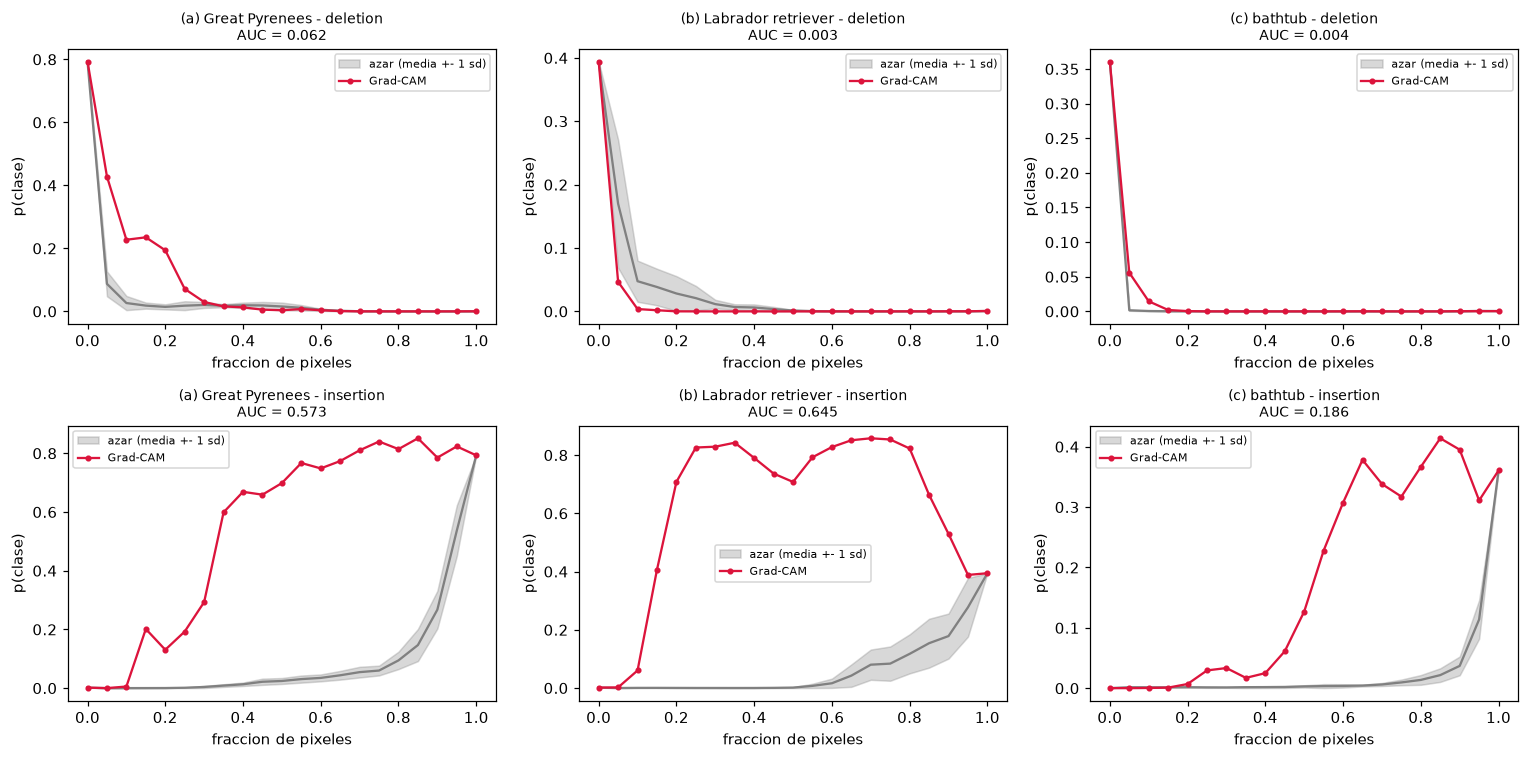

In [27]:
# ---- Task 4.1 ----
import torchvision.transforms.functional as TF
import copy
P = 20                                   # pasos de la curva
N_RAND = 10                              # ordenes aleatorios
NPX = 224
GRAY = 0.5                               # gris medio en [0,1]

def make_rank(order_scores):
    """rank[p] = posicion del pixel p al ordenar por valor descendente (0 = mas importante)."""
    order = torch.argsort(order_scores.flatten().cpu(), descending=True, stable=True)
    rank = torch.empty_like(order); rank[order] = torch.arange(order.numel())
    return rank.view(NPX, NPX)

@torch.no_grad()
def curve(base, rank, ref, c, mode):
    """Probabilidad de la clase c en k = 0..P.
    deletion : los k/P pixeles mas importantes pasan de la imagen a `ref`.
    insertion: los k/P pixeles mas importantes pasan de `ref` a la imagen (ref = version desenfocada)."""
    imgs = []
    for k in range(P + 1):
        m = (rank < round(k / P * NPX * NPX)).unsqueeze(0)             # mascara de la fraccion k/P
        imgs.append(torch.where(m, ref, base) if mode == "del" else torch.where(m, base, ref))
    x = normalize(torch.stack(imgs)).to(device)
    return F.softmax(model(x), dim=1)[:, c].cpu().numpy()          # c_0, ..., c_P

def auc(c_k): return float(np.mean(c_k[1:]))                       # AUC = (1/P) * sum_{k=1}^{P} c_k

BLUR_SIGMA = 10
IMGS41 = {}
for k in "abc":
    base = to_tensor(IM[k][0])
    IMGS41[k] = dict(base=base, gray=torch.full_like(base, GRAY),
                     blur=TF.gaussian_blur(base, kernel_size=6 * BLUR_SIGMA + 1, sigma=BLUR_SIGMA), c=GC[k]["c"])

g41 = torch.Generator().manual_seed(SEED)
RANKS_RAND = {k: [torch.argsort(torch.rand(NPX * NPX, generator=g41)).argsort().view(NPX, NPX) for _ in range(N_RAND)] for k in "abc"}

T41 = {}
for k in "abc":
    d = IMGS41[k]; c = d["c"]; rank_map = make_rank(GC[k]["cam224"])
    r = dict(c=c, name=CLASSES[c])
    r["del_map"] = curve(d["base"], rank_map, d["gray"], c, "del")
    r["ins_map"] = curve(d["base"], rank_map, d["blur"], c, "ins")
    r["del_rand"] = np.stack([curve(d["base"], rr, d["gray"], c, "del") for rr in RANKS_RAND[k]])
    r["ins_rand"] = np.stack([curve(d["base"], rr, d["blur"], c, "ins") for rr in RANKS_RAND[k]])
    T41[k] = r

rows41 = []
for k in "abc":
    r = T41[k]
    for met in ["del", "ins"]:
        a_map = auc(r[f"{met}_map"]); a_rand = np.array([auc(cc) for cc in r[f"{met}_rand"]])
        mu, sd = a_rand.mean(), a_rand.std(ddof=1)
        z = (mu - a_map) / sd if met == "del" else (a_map - mu) / sd      # positivo = el mapa supera al azar
        r[f"auc_{met}"] = dict(map=a_map, rand_mean=float(mu), rand_std=float(sd), diff=float(a_map - mu), z=float(z))
        rows41.append(dict(imagen=k, clase=r["name"], metrica="AUC_" + met, mapa=a_map, azar_media=mu, azar_std=sd,
                           diferencia=a_map - mu, z_mejora=z))
df41 = pd.DataFrame(rows41)
for k in "abc":
    print(f"Imagen ({k}) - clase {T41[k]['name']} (p original = {T41[k]['del_map'][0]:.4f}; p con todo gris = {T41[k]['del_map'][-1]:.4f}; p solo desenfocada = {T41[k]['ins_map'][0]:.4f})")
    print(df41[df41.imagen == k].drop(columns=["imagen", "clase"]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
RES["t4_1"] = {k: {m: T41[k][f"auc_{m}"] for m in ["del", "ins"]} for k in "abc"}

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
xs = np.arange(P + 1) / P
for j, k in enumerate("abc"):
    r = T41[k]
    for i, met in enumerate(["del", "ins"]):
        rr = r[f"{met}_rand"]; a = ax[i, j]
        a.fill_between(xs, rr.mean(0) - rr.std(0, ddof=1), rr.mean(0) + rr.std(0, ddof=1), color="gray", alpha=0.3, label="azar (media +- 1 sd)")
        a.plot(xs, rr.mean(0), color="gray"); a.plot(xs, r[f"{met}_map"], color="crimson", marker="o", ms=3, label="Grad-CAM")
        a.set_title(f"({k}) {r['name']} - {'deletion' if met == 'del' else 'insertion'}\nAUC = {r['auc_'+met]['map']:.3f}", fontsize=9)
        a.set_xlabel("fraccion de pixeles"); a.set_ylabel("p(clase)"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("figures/t4_1_curvas.png"); plt.show()

## Task 4.2 - Aleatorizacion de parametros en cascada

Se reinicializan con `reset_parameters()` de PyTorch (inicializacion por defecto) los pesos de `fc`; luego tambien `layer4`, `layer3`, `layer2`, `layer1` y `conv1` (con su `bn1`). Las capas BatchNorm se reinician junto con su bloque, con estadisticas de identidad. En cada etapa se calcula el Grad-CAM de 7x7 (con ReLU) para la clase del modelo original y su correlacion de Spearman con el mapa original. Si tras la ReLU el mapa quedara constante, el Spearman no esta definido (NaN); no ocurre en esta corrida.

Spearman (mapa 7x7 original vs. aleatorizado), clase original fija:
           (a)    (b)    (c)
fc      +0.503 +0.029 -0.391
+layer4 +0.250 +0.098 +0.237
+layer3 +0.049 +0.198 -0.183
+layer2 -0.165 -0.033 +0.075
+layer1 -0.175 -0.039 -0.116
+conv1  +0.204 -0.185 -0.521

Spearman sobre el mapa sin ReLU (referencia):
             a      b      c
fc      +0.482 +0.027 -0.400
+layer4 -0.144 +0.109 +0.322
+layer3 -0.078 +0.217 -0.166
+layer2 +0.053 -0.025 +0.094
+layer1 +0.108 -0.030 +0.049
+conv1  +0.166 -0.162 -0.529

Celdas activas (>0) de 49 tras ReLU:
          a   b   c
fc       35  49  35
+layer4   3  47   9
+layer3  11  49  36
+layer2   3  49  29
+layer1   8  49   8
+conv1    1  49  34


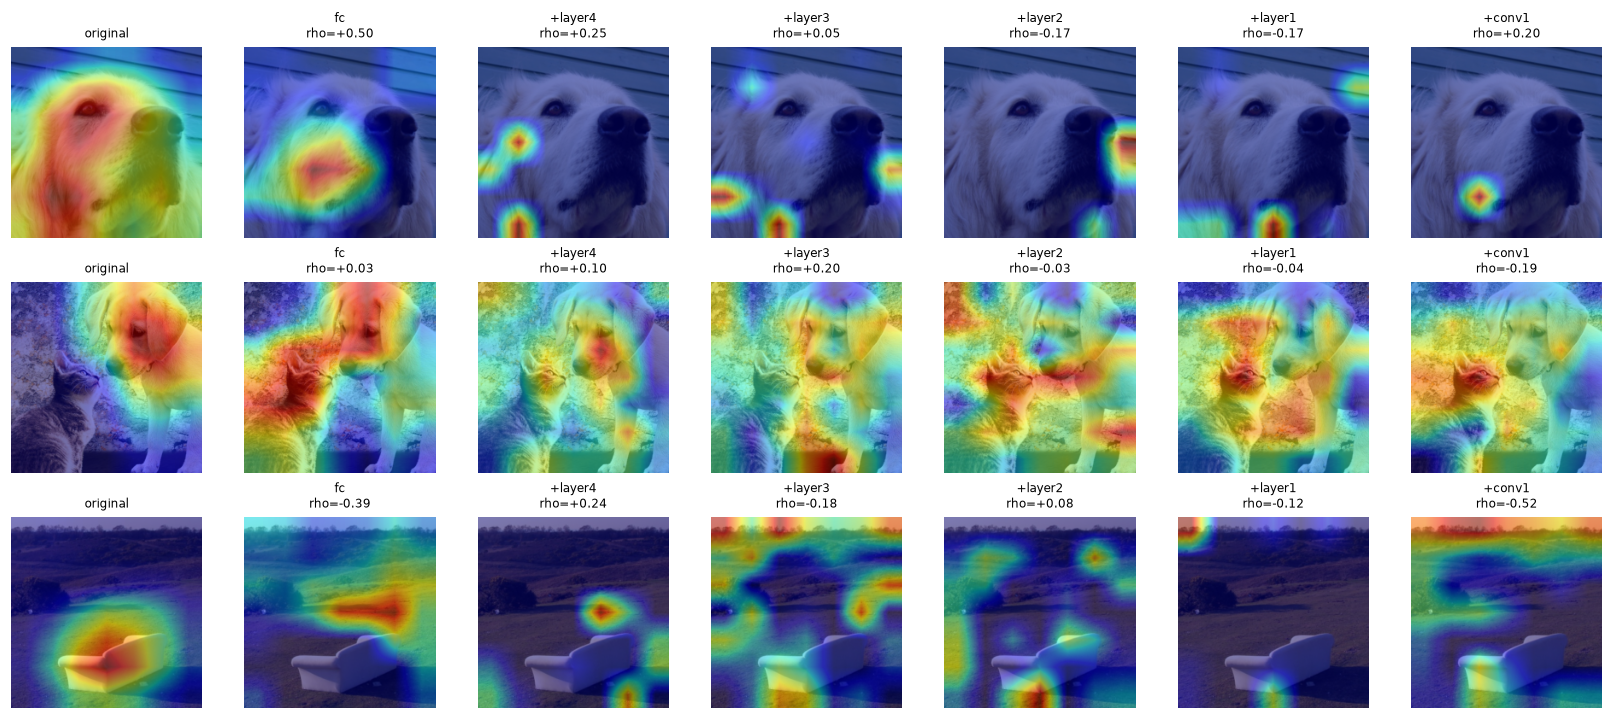

In [28]:
# ---- Task 4.2: aleatorizacion de parametros en cascada ----
STAGES = [("fc", ["fc"]), ("+layer4", ["layer4"]), ("+layer3", ["layer3"]), ("+layer2", ["layer2"]),
          ("+layer1", ["layer1"]), ("+conv1", ["conv1", "bn1"])]       # bn1 acompaña a conv1 (sin ella conv1 queda a medias)

def reinit(module):
    """Inicializacion aleatoria por defecto de PyTorch (reset_parameters) en cada submodulo que la tenga (Conv, Linear, BatchNorm)."""
    for m in module.modules():
        if hasattr(m, "reset_parameters"): m.reset_parameters()

set_seed()
rand_model = copy.deepcopy(model).eval()                  # el modelo original no se toca
gc_rand = GradCAM(rand_model, rand_model.layer4)
CASC = {k: [] for k in "abc"}
for name, mods in STAGES:
    for mn in mods: reinit(getattr(rand_model, mn))       # cascada: las etapas anteriores siguen aleatorias
    for k in "abc":
        c0 = GC[k]["c"]                                    # clase del modelo ORIGINAL, no la nueva prediccion
        g = gc_rand(IM[k][1], c=c0)
        L0, L1 = GC[k]["L"].flatten().cpu().numpy(), g["L"].flatten().cpu().numpy()
        rho = float(spearmanr(L0, L1)[0]) if L1.std() > 0 else float("nan")   # constante (todo 0 tras ReLU) -> indefinido
        rho_raw = float(spearmanr(GC[k]["L_raw"].flatten().cpu().numpy(), g["L_raw"].flatten().cpu().numpy())[0])
        CASC[k].append(dict(etapa=name, spearman=rho, spearman_sin_relu=rho_raw, celdas_activas=int((L1 > 0).sum()),
                            pred_nueva=CLASSES[int(rand_model(IM[k][1]).argmax())]))
gc_rand.remove()
tab42 = pd.DataFrame({k: [r["spearman"] for r in CASC[k]] for k in "abc"}, index=[s[0] for s in STAGES])
tab42.columns = ["(a)", "(b)", "(c)"]
print("Spearman (mapa 7x7 original vs. aleatorizado), clase original fija:")
print(tab42.to_string(float_format=lambda v: f"{v:+.3f}"))
print("\nSpearman sobre el mapa sin ReLU (referencia):")
print(pd.DataFrame({k: [r["spearman_sin_relu"] for r in CASC[k]] for k in "abc"}, index=[s[0] for s in STAGES]).to_string(float_format=lambda v: f"{v:+.3f}"))
print("\nCeldas activas (>0) de 49 tras ReLU:")
print(pd.DataFrame({k: [r["celdas_activas"] for r in CASC[k]] for k in "abc"}, index=[s[0] for s in STAGES]).to_string())
RES["t4_2"] = CASC
fig, ax = plt.subplots(3, 7, figsize=(15, 6.6))
for i, k in enumerate("abc"):
    ax[i, 0].imshow(IM[k][0]); ax[i, 0].imshow(GC[k]["cam224"].cpu().numpy(), cmap="jet", alpha=0.5); ax[i, 0].set_title("original", fontsize=8); ax[i, 0].axis("off")
    ax[i, 0].set_ylabel(k)
# mapas por etapa: se recalculan para dibujar
set_seed(); rm = copy.deepcopy(model).eval(); gcr = GradCAM(rm, rm.layer4)
for j, (name, mods) in enumerate(STAGES):
    for mn in mods: reinit(getattr(rm, mn))
    for i, k in enumerate("abc"):
        g = gcr(IM[k][1], c=GC[k]["c"])
        ax[i, j + 1].imshow(IM[k][0]); ax[i, j + 1].imshow(g["cam224"].cpu().numpy(), cmap="jet", alpha=0.5, vmin=0, vmax=1)
        ax[i, j + 1].set_title(f"{name}\nrho={CASC[k][j]['spearman']:+.2f}", fontsize=8); ax[i, j + 1].axis("off")
gcr.remove()
plt.tight_layout(); plt.savefig("figures/t4_2_cascada.png"); plt.show()
save_res()

## Task 4.3 - Analisis de los resultados

### a. Grad-CAM frente al azar y efecto de los parches grises

En la celda siguiente se repite deletion en la imagen (a) con una referencia desenfocada en lugar de gris, y se agrega una linea base de azar a la resolucion del mapa: un orden aleatorio de las 49 celdas de 32x32 pixeles.

referencia   mapa  azar_media  azar_std  z_mejora
      gris 0.0618      0.0138    0.0035  -13.7038
desenfoque 0.0880      0.0725    0.0073   -2.1269
p(clase) con todos los pixeles reemplazados por la referencia: gris = 0.0004 | desenfoque = 0.0017


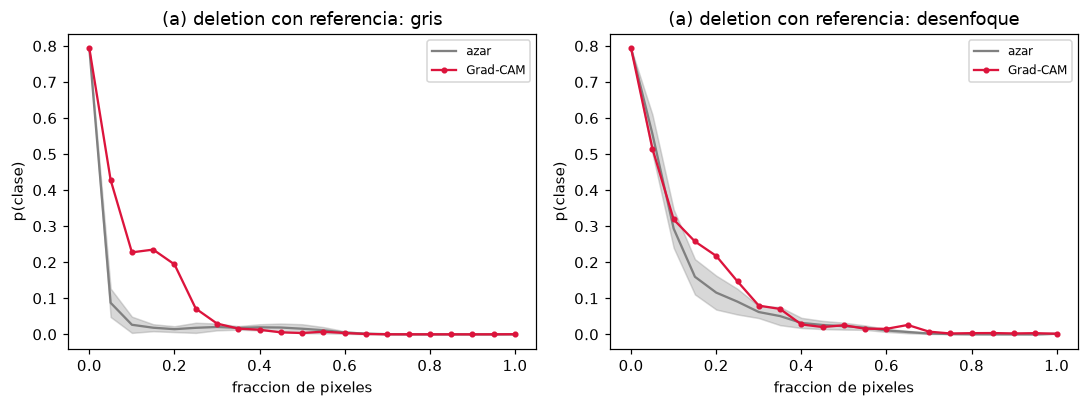

Curva deletion (a), mapa: [0.793 0.428 0.227 0.235 0.194 0.071 0.03  0.016 0.013 0.006 0.004 0.007
 0.004 0.001 0.    0.    0.    0.    0.    0.    0.   ]
Curva insertion (a), mapa: [0.002 0.    0.006 0.202 0.131 0.193 0.293 0.599 0.669 0.659 0.699 0.767
 0.749 0.774 0.81  0.84  0.814 0.851 0.785 0.823 0.793]


imagen metrica   mapa  azar_celdas_media  azar_celdas_std  z_mejora
     a AUC_del 0.0618             0.1833           0.0688    1.7653
     a AUC_ins 0.5728             0.3145           0.0563    4.5859
     b AUC_del 0.0027             0.0932           0.0501    1.8063
     b AUC_ins 0.6445             0.1432           0.0833    6.0213
     c AUC_del 0.0037             0.0136           0.0080    1.2331
     c AUC_ins 0.1860             0.0522           0.0206    6.5057


In [29]:
# ---- Task 4.3a: deletion en la imagen (a) con referencia desenfocada ----
d = IMGS41["a"]; c = d["c"]; rank_map = make_rank(GC["a"]["cam224"])
blur_del_map = curve(d["base"], rank_map, d["blur"], c, "del")
blur_del_rand = np.stack([curve(d["base"], rr, d["blur"], c, "del") for rr in RANKS_RAND["a"]])
a_rand_blur = np.array([auc(cc) for cc in blur_del_rand])
RES["t4_3a"] = dict(
    gris=dict(map=T41["a"]["auc_del"]["map"], rand_mean=T41["a"]["auc_del"]["rand_mean"], rand_std=T41["a"]["auc_del"]["rand_std"]),
    desenfoque=dict(map=auc(blur_del_map), rand_mean=float(a_rand_blur.mean()), rand_std=float(a_rand_blur.std(ddof=1))))
tab43a = pd.DataFrame([dict(referencia=n, mapa=v["map"], azar_media=v["rand_mean"], azar_std=v["rand_std"],
                            z_mejora=(v["rand_mean"] - v["map"]) / v["rand_std"]) for n, v in RES["t4_3a"].items()])
print(tab43a.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("p(clase) con todos los pixeles reemplazados por la referencia: gris =", round(float(T41['a']['del_map'][-1]), 4),
      "| desenfoque =", round(float(blur_del_map[-1]), 4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, (name, cm, cr) in zip(ax, [("gris", T41["a"]["del_map"], T41["a"]["del_rand"]), ("desenfoque", blur_del_map, blur_del_rand)]):
    a.fill_between(xs, cr.mean(0) - cr.std(0, ddof=1), cr.mean(0) + cr.std(0, ddof=1), color="gray", alpha=0.3)
    a.plot(xs, cr.mean(0), color="gray", label="azar"); a.plot(xs, cm, color="crimson", marker="o", ms=3, label="Grad-CAM")
    a.set_title(f"(a) deletion con referencia: {name}"); a.set_xlabel("fraccion de pixeles"); a.set_ylabel("p(clase)"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/t4_3a_referencia.png"); plt.show()
# forma de la curva: el mapa 7x7 se interpola bilinealmente a 224x224; fraccion del area que cubre cada celda 7x7 = 1/49
print("Curva deletion (a), mapa:", np.round(T41["a"]["del_map"], 3))
print("Curva insertion (a), mapa:", np.round(T41["a"]["ins_map"], 3))

# ---- referencia justa: orden aleatorio por CELDAS 7x7 (bloques de 32x32), no por pixel suelto ----
def cell_rank(perm, gen):
    """perm: orden aleatorio de las 49 celdas (perm[i] = celda en la posicion i). Cada pixel hereda la posicion de su celda;
    dentro de una celda el orden es aleatorio (jitter < 1 posicion de celda)."""
    pos = torch.empty(49); pos[perm] = torch.arange(49.)
    cell_of_px = (torch.arange(NPX)[:, None] // 32) * 7 + (torch.arange(NPX)[None, :] // 32)
    return make_rank(-(pos[cell_of_px] + 0.5 * torch.rand(NPX, NPX, generator=gen)))
g43 = torch.Generator().manual_seed(SEED + 1)
rows_cell = []
for k in "abc":
    d = IMGS41[k]; c = d["c"]
    rr = [cell_rank(torch.randperm(49, generator=g43), g43) for _ in range(N_RAND)]
    for met, ref in [("del", d["gray"]), ("ins", d["blur"])]:
        aa = np.array([auc(curve(d["base"], r_, ref, c, met)) for r_ in rr])
        a_map = T41[k][f"auc_{met}"]["map"]; z = (aa.mean() - a_map) / aa.std(ddof=1) if met == "del" else (a_map - aa.mean()) / aa.std(ddof=1)
        rows_cell.append(dict(imagen=k, metrica="AUC_" + met, mapa=a_map, azar_celdas_media=aa.mean(), azar_celdas_std=aa.std(ddof=1), z_mejora=z))
tab_cell = pd.DataFrame(rows_cell); print(tab_cell.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
RES["t4_3a"]["azar_por_celdas"] = rows_cell

**Insertion.** Grad-CAM supera al azar en las tres imagenes: AUC_ins = 0.573, 0.645 y 0.186 contra 0.107, 0.068 y 0.030 del azar por pixel, es decir 54.0, 33.8 y 59.8 desviaciones estandar. Contra el azar por celdas 7x7 sigue ganando, con 4.6, 6.0 y 6.5 desviaciones.

**Deletion.** Aqui depende de la linea base. Contra el azar por pixel solo gana en (b): 0.0027 contra 0.0168, z = +1.8. En (a) y (c) pierde: 0.0618 contra 0.0138 (z = -13.7) y 0.0037 contra 0.0002 (z = -53.1). La causa no es que el mapa sea malo: el azar por pixel reparte gris por toda la imagen y ese patron de ruido fuera de distribucion destruye la prediccion con solo el 5% de pixeles (en (a), p baja de 0.793 a 0.09), mientras que Grad-CAM borra un bloque contiguo y deja el resto del objeto visible (p = 0.43 con el 5%). Con el azar por celdas, que tiene la misma resolucion que el mapa, Grad-CAM gana tambien en deletion: AUC_del 0.0618, 0.0027 y 0.0037 contra 0.183, 0.093 y 0.014, con z = +1.8, +1.8 y +1.2.

**Forma de las curvas.** El mapa tiene 49 posiciones interpoladas bilinealmente, asi que cada celda cubre cerca del 2% de la imagen (1/49) y un paso de 5% equivale a unas 2.5 celdas. El orden entre pixeles vecinos es una rampa suave dentro de cada celda y los saltos grandes ocurren al cruzar de una celda a otra. Por eso las curvas bajan y suben por tramos y no siempre son monotonas: en (a) deletion cae de 0.793 a 0.428 y 0.227 con el 5% y el 10%, sube a 0.235 en el 15% y llega a 0.03 en el 30%; insertion en (a) pasa de 0.01 en el 10% a 0.20 en el 15% y de 0.29 a 0.60 entre el 30% y el 35%. En (b) la insertion llega a 0.86 con el 70% de los pixeles y termina en 0.39 con la imagen completa: las celdas mejor ordenadas bastan para la clase y el resto de la imagen aporta evidencia de otras clases (la imagen tiene dos animales). En (c) la insertion sube tarde (0.06 en el 45% y 0.41 en el 85%) y su maximo, 0.41, queda cerca de la probabilidad original, 0.361: el mapa no concentra la evidencia de bathtub en pocas celdas.

**Parches grises.** Con referencia desenfocada, el AUC_del de Grad-CAM en (a) pasa de 0.0618 a 0.0880, pero el del azar por pixel pasa de 0.0138 a 0.0725, cinco veces mas, y z sube de -13.7 a -2.1. Entonces el gris explica la mayor parte de la desventaja aparente del mapa frente al azar por pixel, pero no toda: con desenfoque el mapa sigue sin superar al azar por pixel. El desenfoque tambien conserva algo de la forma del objeto, por lo que la probabilidad con todos los pixeles reemplazados sube de 0.0004 a 0.0017. La conclusion practica es que el AUC de deletion cambia segun la referencia y la linea base, y debe reportarse junto a ellas.

### b. Etapa en que cae el Spearman y prediccion para `fc`

In [30]:
# prediccion para 4.3b: solo fc aleatoria -> alpha_k = w_k/Z con w nuevos, L = ReLU(sum_k w_k A^k / Z)
set_seed(); m_fc = copy.deepcopy(model).eval(); reinit(m_fc.fc)
for k in "abc":
    A = GC[k]["A"]; w_new = m_fc.fc.weight.detach()[GC[k]["c"]]; w_old = W[GC[k]["c"]]
    cam_new = F.relu((w_new[:, None, None] * A).sum(0)); cam_old_lin = (w_old[:, None, None] * A).sum(0)
    corr_w = float(np.corrcoef(w_new.cpu().numpy(), w_old.cpu().numpy())[0, 1])
    print(f"({k}) corr(w_nuevo, w_viejo) = {corr_w:+.3f} | spearman(CAM con w nuevo, CAM con w viejo) = {float(spearmanr(cam_new.flatten().cpu(), cam_old_lin.flatten().cpu())[0]):+.3f}")

(a) corr(w_nuevo, w_viejo) = -0.023 | spearman(CAM con w nuevo, CAM con w viejo) = +0.503
(b) corr(w_nuevo, w_viejo) = +0.017 | spearman(CAM con w nuevo, CAM con w viejo) = +0.027
(c) corr(w_nuevo, w_viejo) = +0.008 | spearman(CAM con w nuevo, CAM con w viejo) = -0.391


**Etapa en que el Spearman cae bajo 0.3.** Segun la tabla del Task 4.2: en (a) fue en `+layer4` (de 0.503 con solo `fc` a 0.250); en (b) ya con solo `fc` (0.029); en (c) tambien con solo `fc` (-0.391). Luego los valores se quedan cerca de cero o negativos en las tres imagenes (de -0.52 a +0.25), sin volver a subir de 0.3. Con 49 celdas y una sola inicializacion (semilla 42) estos valores son ruidosos: sirven para ver el orden de magnitud, no para comparar etapas cercanas.

**Prediccion para `fc`.** Si solo cambia `fc`, las activaciones A^k de `layer4` no cambian y alpha_k^c = w_k^c / Z con Z = 49, de modo que el mapa es ReLU(sum_k w_k A^k / Z) con los pesos nuevos. Esos pesos no tienen relacion con los originales (correlacion -0.023, 0.017 y 0.008 por imagen), por lo que el mapa es una combinacion aleatoria de los mismos 512 canales y se espera un Spearman cercano a 0. La primera etapa lo confirma en (b), 0.029. En (c) es -0.391, un valor negativo moderado, y en (a) es +0.503, mas alto de lo esperado: los 512 canales son no negativos (salen de una ReLU) y comparten una estructura espacial comun (zonas de alta activacion), por lo que cualquier combinacion de ellos conserva parte de la distribucion espacial original. La formula alpha = w/Z reproduce el resultado de la etapa de `fc`: 0.503, 0.027 y -0.391 contra 0.503, 0.029 y -0.391 obtenidos con autograd (la diferencia de 0.002 en (b) viene de que en esta verificacion el mapa original se compara sin ReLU). Que el mapa cambie al aleatorizar los pesos es lo que se pide a una explicacion que depende del modelo; que en (a) quede una correlacion de 0.5 avisa de que parte de su estructura viene de las activaciones y no del clasificador.

### c. Explicaciones del modelo de credito segun la audiencia

Cifras propias usadas: eficiencia de SHAP con error maximo de 7.8e-16 en el Shapley exacto de 6 variables (Task 2.5) y 2.1e-8 frente a TreeSHAP; KernelSHAP frente a TreeSHAP con MAE de 0.036 a 0.042 (15% a 17% relativo, Task 2.4); LIME con Jaccard de 0.439 (N = 500), 0.754 (N = 5000) y 0.907 (N = 100000), y R2 ponderado de 0.289 con K = 5 (Task 3.5); el contrafactual mas cercano del cliente rechazado cambia solo `checking_status` y sube p(good) de 0.0997 a 0.6538 (Task 3.4).

**Persona solicitante.** Entregaria las tres razones principales de SHAP en lenguaje simple (duration, -1.4586 log-odds; checking_status, -0.9268; installment_commitment, -0.3270) y el contrafactual mas cercano solo con variables que puede modificar: cambiar `checking_status` a no checking lleva el modelo a 0.6538. Respaldo: SHAP cumple eficiencia con error del orden de 1e-8 o menor, y el contrafactual se verifico con el propio modelo. Debe decir que es un resultado del modelo y no una promesa de aprobacion. No entregaria LIME (R2 de 0.289 y Jaccard de 0.754 a N = 5000), ni valores en log-odds sin traducir, ni explicaciones apoyadas en variables inmutables como `personal_status` o `age`.

**Oficial de cumplimiento interno.** SHAP local y global, con su validacion: eficiencia, acuerdo de KernelSHAP con TreeSHAP (MAE de 0.04) y el efecto de variables redundantes, ya que al duplicar `credit_amount` (correlacion 0.9988) la importancia se reparte entre la original y la copia. LIME solo como contraste secundario, con su estabilidad (Jaccard de 0.754 a N = 5000, 0.907 a N = 100000) y su R2 declarados. Tambien el conjunto de contrafactuales para revisar si los cambios sugeridos son razonables. No entregaria una sola corrida de LIME como evidencia.

**Regulador.** Documentacion del metodo: SHAP con las pruebas de eficiencia y de acuerdo entre algoritmos, la discrepancia observada entre LIME y SHAP (personal_status en el puesto 19 contra el 10), y una declaracion explicita de que LIME no alcanza la fidelidad exigida (0.289 frente a 0.80) y por eso no se usa como base de decisiones. Para imagenes, la prueba de aleatorizacion de este task. No entregaria contrafactuales individuales como si garantizaran un resultado ni explicaciones sin sus limites: describen el modelo, no relaciones causales.

**Riesgo de un contrafactual en deteccion de lavado.** En credito, quien recibe el contrafactual quiere que lo aprueben y el cambio sugerido es legitimo. En lavado, el destinatario puede ser quien quiere evadir la deteccion: el contrafactual le dice cual es el cambio minimo para que el modelo no lo marque (por ejemplo, partir montos o cambiar canal). En el Task 3.4 el 29.14% de los candidatos cruzo el umbral y el mas cercano exigia un solo cambio a distancia 1.06, es decir, evadir cuesta poco y es facil de encontrar. Ademas avisar a una persona investigada que fue marcada puede constituir un aviso indebido. En su lugar entregaria al analista interno razones basadas en SHAP (que variables elevaron el riesgo) para investigar el caso, al regulador la documentacion global y las validaciones, y a la persona marcada ninguna explicacion del modelo salvo la que exija la ley, sin ningun cambio que revierta la alerta.